# Malik — Adaptive Fusion BGE-M3 + E5 (Colab)

Tugas kelompok Adaptive Fusion (PJ Faza). Notebook ini memperbaiki notebook pengguna,
memakai BGE sebagai baseline dan E5 sebagai komponen/pembanding. **Metode tugas ini
adalah fusion embedding, bukan LDA/FastText/BiLSTM pada jalur proposal sebelumnya.**

Pilih **Runtime → Change runtime type → T4 GPU**, simpan workbook di
`MyDrive/Rekomendasi_Wisata/koreksi_dataset.xlsx`, lalu Run all. Cakupan default
adalah seluruh workbook Jawa Timur, bukan filter Madura. Folder cache/output/PDF
disimpan di Drive. Hasil real dan mock dipisahkan. PDF diperbarui setiap tahap;
CSV menyimpan seluruh nilai. PDF pada tahap gagal tetap memuat error.

Baseline BGE tidak dilatih ulang. Embedding dipakai ulang hanya bila manifest dan
checksum cocok; cache lama tanpa identitas penuh tidak diasumsikan valid.
`FUSION_RUN_MODE=smoke` hanya untuk uji kode, bukan hasil penelitian.
Paper/riwayat koreksi data yang disebut notebook sumber belum semuanya diverifikasi.


In [1]:
import os, sys, subprocess
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import uuid
RUN_MODE = os.environ.get('FUSION_RUN_MODE', 'research')  # Colab: research atau smoke
MOCK = RUN_MODE == 'smoke'
os.environ['MOCK_ENCODER'] = '1' if MOCK else '0'
try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path('/content/Recomendation_System_fusion')
    if not repo.exists():
        subprocess.run(['git', 'clone', '--depth', '1', '--branch', 'feat/malik-adaptive-fusion-colab',
                        'https://github.com/MalikHariyanto/Recomendation_System.git', str(repo)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(repo/'requirements-fusion-colab.txt')], check=True)
    sys.path.insert(0, str(repo))
    WORK_DIR = '/content/drive/MyDrive/Rekomendasi_Wisata'
else:
    repo = Path(os.environ.get('FUSION_REPO', '.')).resolve()
    sys.path.insert(0, str(repo))
    WORK_DIR = os.environ.get('WORK_DIR', '.')
DATA_NAME = 'koreksi_dataset.xlsx'
os.makedirs(WORK_DIR, exist_ok=True)
os.environ.setdefault('HF_HOME', os.path.join(WORK_DIR, 'hf_cache'))
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
from wisata.pdf_results import ResultRecorder
RUN_ID = os.environ.get('FUSION_RUN_ID') or (datetime.now(ZoneInfo('Asia/Bangkok')).strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
REPORT_DIR = os.path.join(WORK_DIR, 'reports_mock' if MOCK else 'reports_research', RUN_ID)
recorder = ResultRecorder(REPORT_DIR, MOCK)
display = recorder.display
print('Malik | Adaptive Fusion | Mode:', RUN_MODE, '| Folder:', WORK_DIR)
print('Repository SHA:', subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'], text=True).strip())


Mounted at /content/drive
Malik | Adaptive Fusion | Mode: research | Folder: /content/drive/MyDrive/Rekomendasi_Wisata
Repository SHA: 410589b89819c16fdf7aefb6fe67a49ae9a6ea7a


In [2]:
with recorder.stage('Tahap 02 - Malik — Adaptive Fusion BGE-M3 + E5 (Colab)'):
    import re, glob, json, math, time, random, copy, hashlib, warnings
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import matplotlib.pyplot as plt
    from scipy import stats
    from sklearn.model_selection import GroupKFold, GroupShuffleSplit
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA, TruncatedSVD
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics import cohen_kappa_score

    from ftfy import fix_text

    # Warning penting tidak disembunyikan.
    if MOCK: torch.set_num_threads(2)
    pd.set_option('display.max_colwidth', 120)
    _original_show = plt.show
    def _show(*args, **kwargs):
        recorder.capture_figures()
        _original_show(*args, **kwargs)
        plt.close('all')
    plt.show = _show


In [3]:
with recorder.stage('Tahap 03 - Malik — Adaptive Fusion BGE-M3 + E5 (Colab)'):
    # ── 1. Konfigurasi eksperimen ──
    CFG = dict(
        seed            = 42,
        bge_revision = '5617a9f61b028005a4858fdac845db406aefb181',
        e5_revision = '3d7cfbdacd47fdda877c5cd8a79fbcc4f2a574f3',
        bge_model       = 'BAAI/bge-m3',
        e5_model        = 'intfloat/multilingual-e5-large',
        e5_query_prefix = 'query: ',
        e5_doc_prefix   = 'passage: ',
        max_len         = 256,
        batch_size      = 64,
        topm            = 5,      # skor destinasi = rata-rata top-m skor ulasannya
        min_words       = 3,      # ulasan < 3 kata dibuang (tidak informatif)
        n_known_item    = 4000,   # jumlah query Protokol B
        k               = 10,
        tau             = 0.5,    # temperatur ListNet
        gate_hidden     = 32,
        gate_dropout    = 0.1,
        gate_lr         = 3e-3,
        gate_wd         = 1e-3,
        gate_epochs     = 400,
        gate_patience   = 40,
        ctx_dropout     = 0.2,    # peluang konteks musim disembunyikan saat latih
        gate_seeds      = [0, 1, 2],
        pca_dim         = 16,
        n_folds         = 5,
        lam_grid        = np.round(np.linspace(0, 1, 21), 2),
        n_boot          = 1000,
    )
    if MOCK:
        CFG.update(n_known_item=200, gate_epochs=20, gate_patience=5, gate_seeds=[0], mock_cap=8, n_folds=3, n_boot=100)

    def set_seed(s):
        random.seed(s); np.random.seed(s); torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)

    set_seed(CFG['seed'])
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    DTYPE  = torch.float16 if DEVICE == 'cuda' else torch.float32

    OUT_DIR = os.environ.get('OUT_DIR', os.path.join(WORK_DIR, 'output_fusion_mock' if MOCK else 'output_fusion_research', RUN_ID))
    CACHE   = os.path.join(WORK_DIR, 'cache_embeddings' + ('_mock' if MOCK else ''))   # dipakai bersama notebook 1–3
    os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(CACHE, exist_ok=True)

    def find_data():
        cands = [os.environ.get('DATA_PATH', ''), os.path.join(WORK_DIR, DATA_NAME), os.path.join('/content', DATA_NAME), DATA_NAME]
        for p in cands:
            if p and os.path.exists(p):
                return p
        if IS_COLAB:   # belum ada di Drive → unggah manual, lalu disimpan ke folder kerja
            from google.colab import files
            print(f'{DATA_NAME} tidak ditemukan di {WORK_DIR}. Silakan unggah file tersebut:')
            up = files.upload()
            if DATA_NAME in up:
                dst = os.path.join(WORK_DIR, DATA_NAME)
                with open(dst, 'wb') as f:
                    f.write(up[DATA_NAME])
                return dst
        raise FileNotFoundError(f'{DATA_NAME} tidak ditemukan (letakkan di {WORK_DIR})')

    DATA_PATH = find_data()
    if not MOCK and DEVICE != 'cuda':
        raise RuntimeError('Run penelitian memerlukan GPU. Aktifkan T4 di Colab; gunakan smoke hanya untuk tes kode.')
    if IS_COLAB and DEVICE != 'cuda':
        print('⚠️ GPU tidak aktif — pilih Runtime → Change runtime type → T4 GPU, lalu jalankan ulang.')
    print('Device  :', DEVICE, '| MOCK :', MOCK)
    print('Data    :', DATA_PATH)
    print('Output  :', OUT_DIR)
    print('Cache   :', CACHE)
    DATASET_SHA256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
    display(print('Dataset SHA256:', DATASET_SHA256))

koreksi_dataset.xlsx tidak ditemukan di /content/drive/MyDrive/Rekomendasi_Wisata. Silakan unggah file tersebut:


Saving koreksi_dataset.xlsx to koreksi_dataset.xlsx
Device  : cuda | MOCK : False
Data    : /content/drive/MyDrive/Rekomendasi_Wisata/koreksi_dataset.xlsx
Output  : /content/drive/MyDrive/Rekomendasi_Wisata/output_fusion_research/20261026_013728_f26eb3
Cache   : /content/drive/MyDrive/Rekomendasi_Wisata/cache_embeddings
Dataset SHA256: 84245d7276d9ea14014be983f0a0a0385685c20ae08ff43817fecd5b2329e527


## 2. Data understanding & preparation
- **Dataset:** `koreksi_dataset.xlsx` (79.514 ulasan, 207 destinasi; kolom `id_destinasi, destinasi, rating, date, text_original, text_preprocessed, rekomendasi_cuaca, wisata`). Dataset ini adalah versi terkoreksi dari `Hasil_Mapping_Ulasan_Wisata.xlsx`: pada file lama, 84 dari 207 label `destinasi` (33.205 baris ulasan) tertempel pada kelompok ulasan yang salah (mis. kelompok "Sedudo" berisi ulasan Selecta) dan kategori `wisata` ikut bergeser. Nama dipulihkan secara deterministik dari urutan `id_destinasi` (identik dengan urutan nama mentah data asli) dan kategori diverifikasi ulang; teks, rating, tanggal, dan label musim tidak diubah. Rincian perubahan per destinasi ada di `koreksi_destinasi.xlsx`.
- Teks yang di-*embed* adalah `text_original` (model kontekstual tidak butuh stemming/stopword removal); hanya diperbaiki mojibake-nya dan dirapikan spasi.
- Ulasan < 3 kata dan duplikat (destinasi, teks) dibuang.
- Setiap destinasi memiliki satu kategori (`wisata`) dan satu label musim (`rekomendasi_cuaca`).

In [4]:
with recorder.stage('Tahap 05 - 2. Data understanding & preparation'):
    df_raw = pd.read_excel(DATA_PATH)
    print('Ukuran awal :', df_raw.shape)

    df = df_raw.copy()
    df['wisata'] = df['wisata'].fillna('lainnya').astype(str).str.strip().str.lower()
    df['text']   = (df['text_original'].fillna('').astype(str).map(fix_text)
                    .str.replace(r'\s+', ' ', regex=True).str.strip())
    df = df[df['text'].str.split().str.len() >= CFG['min_words']]
    df = df.drop_duplicates(['destinasi', 'text'])

    if MOCK:   # subsample per destinasi agar cepat di CPU
        df = df.sample(frac=1, random_state=CFG['seed'])
        df = df[df.groupby('destinasi').cumcount() < CFG['mock_cap']]

    # ── Katalog destinasi ──
    dest = (df.groupby('destinasi')
              .agg(wisata=('wisata', lambda s: s.mode().iat[0]),
                   musim=('rekomendasi_cuaca', lambda s: s.mode().iat[0]),
                   n_ulasan=('text', 'size'),
                   rating_mean=('rating', 'mean'))
              .reset_index())
    dest['cocok_hujan']   = dest['musim'].str.contains('Penghujan')
    dest['cocok_kemarau'] = dest['musim'].str.contains('Kemarau')
    D = len(dest)
    dest_id = {d: i for i, d in enumerate(dest['destinasi'])}

    # Urutkan ulasan per destinasi → setiap destinasi = satu segmen kontigu
    df['did'] = df['destinasi'].map(dest_id)
    df = df.sort_values('did', kind='stable').reset_index(drop=True)
    OFFSETS = np.r_[0, np.cumsum(dest['n_ulasan'].values)]
    N = len(df)

    print(f'Ulasan bersih : {N:,} | Destinasi : {D}')
    print(dest['musim'].value_counts().to_string())
    display(dest.head())

Ukuran awal : (79514, 8)
Ulasan bersih : 67,283 | Destinasi : 207
musim
Kemarau & Penghujan    113
Kemarau                 94


,destinasi,wisata,musim,n_ulasan,rating_mean,cocok_hujan,cocok_kemarau
0,Air Dolo,air terjun,Kemarau & Penghujan,448,4.517857,True,True
1,Air Irenggolo,air terjun,Kemarau & Penghujan,246,4.548780,True,True
2,Air Panas Blawan,pemandian,Kemarau,108,4.583333,False,True
3,Air Terjun Coban Kromo,air terjun,Kemarau & Penghujan,33,3.787879,True,True
4,Air Terjun Jurug Warudongko,air terjun,Kemarau,7,5.000000,False,True


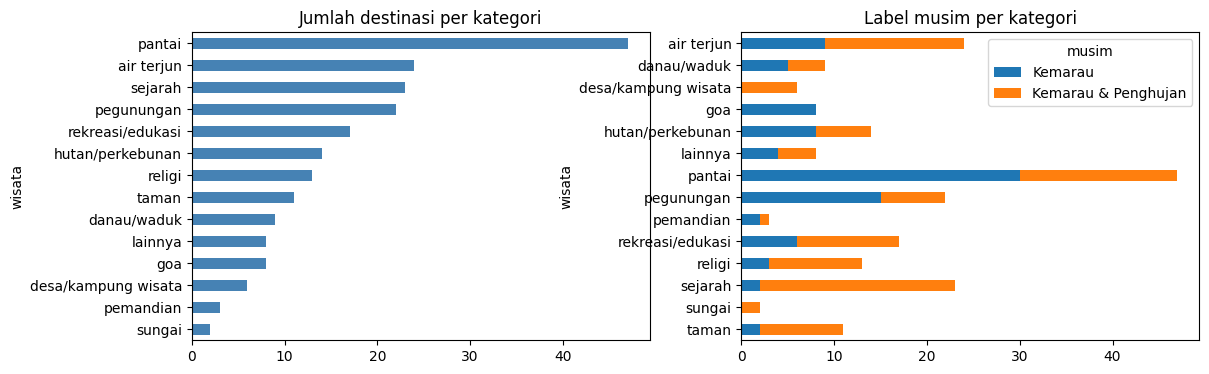

In [5]:
with recorder.stage('Tahap 06 - 2. Data understanding & preparation'):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    dest['wisata'].value_counts().plot.barh(ax=ax[0], color='steelblue')
    ax[0].set_title('Jumlah destinasi per kategori'); ax[0].invert_yaxis()
    pd.crosstab(dest['wisata'], dest['musim']).plot.barh(stacked=True, ax=ax[1])
    ax[1].set_title('Label musim per kategori'); ax[1].invert_yaxis()
    display(plt.show())

## 3. Test collection (ground truth)

Evaluasi lama (relevansi = rating ulasan, unit = ulasan) tidak mengukur **kecocokan destinasi dengan kebutuhan pengguna**. Karena itu dibangun dua protokol yang saling melengkapi:

**Protokol A — Query kebutuhan wisata bertingkat (graded qrels).** Query disusun dari *kategori* (13 kategori + 3 super-kategori: *wisata alam*, *budaya/religi*, *keluarga/buatan*) × *aspek* (8 aspek + tanpa aspek) × *musim* (hujan/kemarau) × *gaya bahasa* (formal, santai, Inggris). Relevansi destinasi $d$:

$$rel(q,d)=\mathbb{1}[\text{kategori cocok}]\cdot\mathbb{1}[\text{cocok musim}]\cdot\big(1+\mathbb{1}[\text{aspek kuat}]\big)\in\{0,1,2\}$$

"Aspek kuat" = proporsi ulasan destinasi yang memuat leksikon aspek berada di atas persentil-60 (sumber leksikal, independen dari kedua model embedding).

**Protokol B — Known-item (leave-one-review-out).** Satu ulasan dijadikan query, dikeluarkan dari indeks, dan destinasi asalnya adalah satu-satunya item relevan. Protokol ini tidak bergantung pada template/label buatan peneliti.

**Protokol C — Query uji skripsi.** Dua query yang dipakai pada skripsi *"Sistem Rekomendasi Pariwisata Jawa Timur Berbasis Seasonal Context-Aware Menggunakan BAAI General Embedding"* (Prasetyo, 2026 [7]):

| Kode | Query | Musim asli | Sumber |
|---|---|---|---|
| S1 | *Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.* | — | Tabel 3.1 |
| S2 | *Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmati udara segar.* | Kemarau | Bab 4 (`input_destinasi`) |

Setiap query diuji pada konteks musim **aslinya** dan pada **variasi konteks** (`none`, `kemarau`, `hujan`) dengan teks yang sama, sehingga terlihat apakah sistem menyesuaikan rekomendasi terhadap musim. Relevansi memakai aturan Protokol A: kategori (S1 → seluruh kategori alam, S2 → air terjun) × cocok musim × (1 + aspek kuat), dengan aspek S1 = {pemandangan, tenang} dan S2 = {sejuk, tenang, pemandangan}; "aspek kuat" = destinasi kuat pada ≥ separuh aspek query. Karena jumlah query sangat sedikit, Protokol C adalah **evaluasi studi kasus** (tidak untuk uji signifikansi) dan angka skripsi tidak dapat dibandingkan langsung karena skripsi memakai rating ulasan sebagai relevansi.

**Protokol D — Query uji berbasis literatur.** Desain query mengikuti praktik penelitian sejenis:

| Penelitian | Cara membangun query uji | Ground truth | Diadopsi sebagai |
|---|---|---|---|
| POINTREC (Afzali, Drzewiecki & Balog, 2021) [1] | 112 permintaan **naratif** nyata dari Reddit & Yahoo! Answers, dianotasi metadata (kategori, kendala, contoh POI) | *pooling* + crowdsourcing, relevansi bertingkat | **D1 — permintaan naratif** beranotasi metadata |
| TourismQA / LAMB (Contractor et al., 2021 [3]; Li, Tomko & Baldwin, 2024 [4]) | pertanyaan forum TripAdvisor; POI direpresentasikan oleh **ulasannya**; *dense bi-encoder* | POI pada jawaban forum | gaya pertanyaan forum di D1 |
| SynthTRIPs (Banerjee et al., 2025) [2] | query sintetis dari **persona** × filter (minat, **bulan**, budget, popularitas = jumlah ulasan, *off-peak*) dalam 4 tingkat kompleksitas; versi *vanilla* vs *persona* | filter terpenuhi pada *knowledge base* | **D2 — persona × kompleksitas** |
| Karlović et al. (2025) [5]; Trattner et al. (2018) [6] | query yang sama dievaluasi pada **konteks cuaca** berbeda | penilaian output / kunjungan nyata | konteks musim implisit melalui **bulan** perjalanan |

- **D1 (20 query naratif)** — gaya unggahan forum (bahasa Indonesia santai dan Inggris), tiap query dianotasi: kategori, bulan/musim, aspek, dan batasan popularitas.
- **D2 (persona × kompleksitas)** — 10 persona (keluarga, backpacker, fotografer, pasangan, pendaki, peziarah, guru, lansia, pekerja *healing*, turis asing) × 4 tingkat: *mudah* (kategori), *sedang* (+ bulan), *sulit* (+ aspek), *berkelanjutan* (+ belum ramai/*off-peak*) × 3 sampel; masing-masing dalam versi **vanilla** dan **persona** (pasangan berpasangan → uji ketahanan terhadap teks persona yang panjang).
- **Musim implisit:** query menyebut **bulan**, bukan kata "hujan/kemarau". Pemetaan (pendekatan pola monsun umum Jawa Timur, dapat disesuaikan): Nov–Mar = `hujan`, Mei–Sep = `kemarau`, April & Oktober = pancaroba → `none`.
- **Relevansi** = kategori cocok × cocok musim × cocok popularitas (bila diminta; tingkat popularitas = tertil jumlah ulasan, seperti SynthTRIPs) × (1 + aspek kuat).

### Daftar pustaka (sumber desain query uji, model, dan metode)

**Penelitian acuan query uji & ground truth**
1. Afzali, J., Drzewiecki, A. M., & Balog, K. (2021). POINTREC: A test collection for narrative-driven point of interest recommendation. In *Proceedings of the 44th International ACM SIGIR Conference on Research and Development in Information Retrieval (SIGIR '21)*. https://doi.org/10.1145/3404835.3463243
2. Banerjee, A., Satish, A., Aisyah, F. N., Wörndl, W., & Deldjoo, Y. (2025). SynthTRIPs: A knowledge-grounded framework for benchmark query generation for personalized tourism recommenders. In *Proceedings of the 48th International ACM SIGIR Conference (SIGIR '25)*. https://doi.org/10.1145/3726302.3730321
3. Contractor, D., Shah, K., Partap, A., Singla, P., & Mausam. (2021). Answering POI-recommendation questions using tourism reviews. In *Proceedings of the 30th ACM International Conference on Information and Knowledge Management (CIKM '21)*. https://doi.org/10.1145/3459637.3482320
4. Li, H., Tomko, M., & Baldwin, T. (2024). Location aware modular biencoder for tourism question answering. *arXiv:2401.02187*. https://arxiv.org/abs/2401.02187
5. Karlović, R., Rovis, M., Smajić, A., Sever, L., & Lorencin, I. (2025). Context-aware tourism recommendations using retrieval-augmented large language models and semantic re-ranking. *Electronics, 14*(22), 4448. https://doi.org/10.3390/electronics14224448
6. Trattner, C., Oberegger, A., Marinho, L., & Parra, D. (2018). Investigating the utility of the weather context for point of interest recommendations. *Information Technology & Tourism*. Preprint: https://christophtrattner.info/pubs/JITT_ctrattner.pdf
7. Prasetyo, S. G. (2026). *Sistem rekomendasi pariwisata Jawa Timur berbasis seasonal context-aware menggunakan BAAI General Embedding* [Skripsi, Program Studi Sistem Informasi, Universitas Trunojoyo Madura]. — sumber query uji Protokol C.

**Penelitian sejenis di Indonesia (pembanding)**

8. Hakim, S. P. R., Suharso, W., & Amiri, Y. I. A. (2026). Penerapan semantic embedding berbasis Sentence-BERT pada sistem rekomendasi pariwisata menggunakan content-based filtering. *Jurnal Penelitian Ilmiah Multidisiplin, 10*(7). https://oaj.jurnalhst.com/index.php/jpim/article/view/23975
9. Universitas Diponegoro. (2026). *Studi komparatif representasi teks TF-IDF dan IndoBERT berbasis content-based filtering menggunakan cosine similarity untuk rekomendasi destinasi wisata* [Skripsi; nama penulis lihat repositori]. https://eprints2.undip.ac.id/id/eprint/43830/

**Model embedding & metode**

10. Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D., & Liu, Z. (2024). BGE M3-Embedding: Multi-lingual, multi-functionality, multi-granularity text embeddings through self-knowledge distillation. *arXiv:2402.03216*. https://arxiv.org/abs/2402.03216
11. Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). Multilingual E5 text embeddings: A technical report. *arXiv:2402.05672*. https://arxiv.org/abs/2402.05672
12. Järvelin, K., & Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems, 20*(4), 422–446. https://doi.org/10.1145/582415.582418
13. Cao, Z., Qin, T., Liu, T.-Y., Tsai, M.-F., & Li, H. (2007). Learning to rank: From pairwise approach to listwise approach (ListNet). In *Proceedings of the 24th International Conference on Machine Learning (ICML '07)*. https://doi.org/10.1145/1273496.1273513
14. Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). Reciprocal rank fusion outperforms Condorcet and individual rank learning methods. In *Proceedings of SIGIR '09*. https://doi.org/10.1145/1571941.1572114
15. Shtok, A., Kurland, O., Carmel, D., Raiber, F., & Markovits, G. (2012). Predicting query performance by query-drift estimation. *ACM Transactions on Information Systems, 30*(2). https://doi.org/10.1145/2180868.2180873

> ⚠️ *Threat to validity*: label `rekomendasi_cuaca` sebelumnya diturunkan dengan BGE-M3, sehingga ada potensi bias sirkular yang menguntungkan BGE pada komponen musim. Hal ini wajib dinyatakan di naskah; Protokol B dan anotasi manusia (Bagian 13) menjadi kontrolnya.

In [6]:
with recorder.stage('Tahap 08 - 3. Test collection (ground truth)'):
    CATS = {   # key: (label kategori di data, frasa formal, frasa santai, frasa Inggris)
        'pantai'      : (['pantai'], 'wisata pantai', 'pantai', 'beach'),
        'air terjun'  : (['air terjun'], 'wisata air terjun', 'air terjun atau coban', 'waterfall'),
        'pegunungan'  : (['pegunungan'], 'wisata pegunungan', 'gunung atau bukit', 'mountain destination'),
        'hutan'       : (['hutan/perkebunan'], 'wisata hutan atau perkebunan', 'hutan pinus atau kebun', 'forest or plantation'),
        'goa'         : (['goa'], 'wisata goa', 'gua', 'cave'),
        'danau'       : (['danau/waduk'], 'wisata danau atau waduk', 'telaga atau waduk', 'lake or reservoir'),
        'pemandian'   : (['pemandian'], 'pemandian air panas', 'kolam pemandian', 'hot spring'),
        'sungai'      : (['sungai'], 'wisata sungai', 'susur sungai', 'river tour'),
        'taman'       : (['taman'], 'taman kota', 'taman buat nongkrong', 'city park'),
        'sejarah'     : (['sejarah'], 'wisata sejarah', 'museum atau candi', 'historical site'),
        'religi'      : (['religi'], 'wisata religi', 'ziarah makam wali atau masjid', 'religious site'),
        'rekreasi'    : (['rekreasi/edukasi'], 'tempat rekreasi dan edukasi', 'taman bermain keluarga', 'theme park or educational attraction'),
        'desa wisata' : (['desa/kampung wisata'], 'desa wisata', 'kampung wisata', 'tourism village'),
        # super-kategori
        'ALAM'        : (['pantai', 'air terjun', 'pegunungan', 'hutan/perkebunan', 'goa', 'danau/waduk', 'pemandian', 'sungai'],
                         'wisata alam', 'tempat wisata alam', 'nature destination'),
        'BUDAYA'      : (['sejarah', 'religi', 'desa/kampung wisata'], 'wisata budaya dan religi', 'wisata budaya', 'cultural or religious destination'),
        'KELUARGA'    : (['taman', 'rekreasi/edukasi'], 'wisata keluarga', 'tempat main buat keluarga', 'family attraction'),
    }

    ASPECTS = {   # key: (formal, santai, Inggris, leksikon untuk relevansi)
        'sejuk'      : ('berudara sejuk dan segar', 'yang adem', 'with cool fresh air', ['sejuk', 'adem', 'dingin', 'segar', 'udaranya']),
        'pemandangan': ('dengan pemandangan indah', 'yang viewnya bagus', 'with beautiful scenery', ['pemandangan', 'view', 'panorama', 'sunset', 'sunrise', 'indah']),
        'keluarga'   : ('yang ramah keluarga dan anak', 'buat bawa anak', 'that is family friendly', ['keluarga', 'anak', 'anak2', 'family']),
        'murah'      : ('dengan tiket murah', 'yang murah meriah', 'with cheap tickets', ['murah', 'terjangkau', 'gratis', 'ekonomis']),
        'foto'       : ('dengan spot foto menarik', 'yang instagramable', 'with instagrammable photo spots', ['foto', 'spot', 'instagramable', 'instagramable', 'selfie', 'estetik']),
        'tenang'     : ('dengan suasana tenang', 'yang sepi dan tenang', 'with a calm atmosphere', ['tenang', 'sepi', 'damai', 'asri', 'hening']),
        'bersih'     : ('yang bersih dan terawat', 'yang bersih', 'that is clean and well maintained', ['bersih', 'terawat', 'rapi']),
        'akses'      : ('dengan akses mudah', 'yang gampang dijangkau', 'with easy access', ['akses', 'parkir', 'dijangkau', 'terjangkau', 'jalannya']),
    }

    SEASON_TXT = {'hujan'  : ('saat musim hujan', 'pas lagi musim hujan', 'during the rainy season'),
                  'kemarau': ('saat musim kemarau', 'pas kemarau yang panas', 'during the dry season')}

    # ── Kekuatan aspek per destinasi (leksikal) ──
    low = df['text'].str.lower()
    asp_frac = pd.DataFrame({a: low.str.contains(r'\b(?:' + '|'.join(map(re.escape, v[3])) + r')\b', regex=True)
                             for a, v in ASPECTS.items()}).groupby(df['did']).mean()
    asp_strong = ((asp_frac > 0) & (asp_frac >= asp_frac.quantile(0.6))).reindex(range(D), fill_value=False)

    def make_query(cat, asp, season, style):
        c = CATS[cat][1 + style]
        a = ASPECTS[asp][style] if asp else ''
        s = SEASON_TXT[season][style]
        if style == 0:
            return f'Rekomendasi {c} {a} {s}'.replace('  ', ' ')
        if style == 1:
            return f'cari {c} {a} buat liburan {s}'.replace('  ', ' ')
        return f'Recommend a {c} {a} to visit {s}'.replace('  ', ' ')

    rows, rel_rows = [], []
    for cat, (labels, *_) in CATS.items():
        cat_ok = dest['wisata'].isin(labels).values
        for season in ['hujan', 'kemarau']:
            season_ok = dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values
            base = (cat_ok & season_ok).astype(np.int8)
            for asp in [None] + list(ASPECTS):
                rel = base * (1 + asp_strong[asp].values.astype(np.int8)) if asp else base
                if rel.sum() == 0 or (rel > 0).all():
                    continue
                for style, lang in enumerate(['id_formal', 'id_santai', 'en']):
                    rows.append(dict(text=make_query(cat, asp, season, style), cat=cat, aspect=asp or '-',
                                     season=season, lang=lang, n_rel=int((rel > 0).sum())))
                    rel_rows.append(rel)

    QA   = pd.DataFrame(rows)
    RELA = np.vstack(rel_rows).astype(np.int8)
    print(f'Protokol A: {len(QA)} query | rata-rata destinasi relevan/query = {QA.n_rel.mean():.1f}')
    display(QA.sample(8, random_state=1))

Protokol A: 837 query | rata-rata destinasi relevan/query = 19.9


,text,cat,aspect,season,lang,n_rel
824,Recommend a family attraction with cheap tickets to visit during the dry season,KELUARGA,murah,kemarau,en,28
255,Rekomendasi wisata danau atau waduk dengan tiket murah saat musim hujan,danau,murah,hujan,id_formal,4
238,cari gua yang bersih buat liburan pas kemarau yang panas,goa,bersih,kemarau,id_santai,8
809,Recommend a family attraction with easy access to visit during the rainy season,KELUARGA,akses,hujan,en,20
216,Rekomendasi wisata goa saat musim kemarau,goa,-,kemarau,id_formal,8
385,cari susur sungai yang viewnya bagus buat liburan pas kemarau yang panas,sungai,pemandangan,kemarau,id_santai,2
452,Recommend a city park with a calm atmosphere to visit during the dry season,taman,tenang,kemarau,en,11
453,Rekomendasi taman kota yang bersih dan terawat saat musim kemarau,taman,bersih,kemarau,id_formal,11


In [7]:
with recorder.stage('Tahap 09 - 3. Test collection (ground truth)'):
    # ── Protokol B: known-item (leave-one-review-out) ──
    rng = np.random.default_rng(CFG['seed'])
    elig = df[df['text'].str.split().str.len() >= 12]
    elig = elig.sample(frac=1, random_state=CFG['seed'])
    elig = elig[elig.groupby('did').cumcount() < 20]                 # maksimal 20 query per destinasi
    elig = elig[dest['n_ulasan'].values[elig['did'].values] > CFG['topm'] + 1]
    selB = elig.sample(min(CFG['n_known_item'], len(elig)), random_state=CFG['seed'])

    QB_ = pd.DataFrame({'text': selB['text'].values, 'did': selB['did'].values, 'season': 'none'})
    EXCL_B = selB.index.values.astype(np.int64)                       # posisi ulasan yang dikeluarkan dari indeks
    RELB = np.zeros((len(QB_), D), np.int8); RELB[np.arange(len(QB_)), QB_['did'].values] = 1
    print(f'Protokol B: {len(QB_)} query known-item dari {QB_.did.nunique()} destinasi')

    # Simpan test collection (dapat dirilis sebagai kontribusi data)
    QA.assign(qid=range(len(QA))).to_csv(f'{OUT_DIR}/queries_protokolA.csv', index=False)
    pd.DataFrame([(i, dest.destinasi[j], int(RELA[i, j])) for i, j in zip(*np.nonzero(RELA))],
                 columns=['qid', 'destinasi', 'rel']).to_csv(f'{OUT_DIR}/qrels_protokolA.csv', index=False)

    # ── Protokol C: query uji skripsi (Prasetyo, 2026) ──
    QUERY_SKRIPSI = [
        dict(kode='S1', text='Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.',
             cats=CATS['ALAM'][0], aspects=['pemandangan', 'tenang'], musim_asli='none', sumber='Tabel 3.1'),
        dict(kode='S2', text='Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, '
                             'cocok untuk relaksasi dan menikmati udara segar.',
             cats=['air terjun'], aspects=['sejuk', 'tenang', 'pemandangan'], musim_asli='kemarau', sumber='Bab 4 (input_destinasi)'),
    ]
    rows, rel_rows = [], []
    for q in QUERY_SKRIPSI:
        cat_ok = dest['wisata'].isin(q['cats']).values
        strong = asp_strong[q['aspects']].values.sum(1) >= math.ceil(len(q['aspects']) / 2)
        for season in ['none', 'kemarau', 'hujan']:
            season_ok = (np.ones(D, bool) if season == 'none'
                         else dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values)
            rel = (cat_ok & season_ok).astype(np.int8) * (1 + strong.astype(np.int8))
            rows.append(dict(qid=f"{q['kode']}-{season}", kode=q['kode'], text=q['text'], season=season,
                             status='asli skripsi' if season == q['musim_asli'] else 'variasi musim',
                             sumber=q['sumber'], n_rel=int((rel > 0).sum()), n_rel_kuat=int((rel == 2).sum())))
            rel_rows.append(rel)
    QC   = pd.DataFrame(rows)
    RELC = np.vstack(rel_rows).astype(np.int8)
    print(f'Protokol C: {len(QC)} query uji skripsi (2 teks × 3 konteks musim)')
    display(QC[['qid', 'status', 'season', 'n_rel', 'n_rel_kuat', 'text']])
    QC.to_csv(f'{OUT_DIR}/queries_protokolC.csv', index=False)

    # ── Protokol D: query uji berbasis literatur (POINTREC, TourismQA, SynthTRIPs) ──
    BULAN    = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']
    BULAN_EN = dict(zip(BULAN, ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']))
    MUSIM_BULAN = {**{b: 'hujan' for b in ['November', 'Desember', 'Januari', 'Februari', 'Maret']},
                   **{b: 'kemarau' for b in ['Mei', 'Juni', 'Juli', 'Agustus', 'September']},
                   'April': 'none', 'Oktober': 'none'}          # pancaroba → konteks musim tidak pasti
    POP_TIER = pd.qcut(dest['n_ulasan'].rank(method='first'), 3, labels=['rendah', 'sedang', 'tinggi']).astype(str).values

    def qrels_dari_meta(cats, season, aspects=(), pop=None):
        cat_ok = dest['wisata'].isin(cats).values
        season_ok = (np.ones(D, bool) if season == 'none'
                     else dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values)
        pop_ok = np.ones(D, bool) if pop is None else (POP_TIER == pop)
        base = (cat_ok & season_ok & pop_ok).astype(np.int8)
        if not aspects:
            return base
        strong = asp_strong[list(aspects)].values.sum(1) >= math.ceil(len(aspects) / 2)
        return base * (1 + strong.astype(np.int8))

    ALAM = CATS['ALAM'][0]
    # D1 — permintaan naratif gaya forum (POINTREC / TourismQA), dianotasi manual
    NARATIF = [
        ('Halo kak, rencana liburan akhir Desember bareng keluarga, anak-anak masih SD. Mau cari wisata alam yang aman buat anak dan jalannya nggak terlalu susah, soalnya pasti sering hujan. Ada rekomendasi?', ALAM, 'Desember', ['keluarga', 'akses'], None, 'id'),
        ('Aku sama pasangan pengen tempat yang sepi dan tenang buat lihat sunset bulan Agustus nanti. Lebih suka pantai yang belum terlalu ramai.', ['pantai'], 'Agustus', ['tenang', 'pemandangan'], 'rendah', 'id'),
        ('Saya guru SD, mau mengajak murid study tour bulan Mei. Butuh tempat wisata edukasi atau sejarah yang bisa untuk belajar dan aman untuk anak-anak.', ['sejarah', 'rekreasi/edukasi'], 'Mei', ['keluarga'], None, 'id'),
        ('Ada yang tahu air terjun yang airnya jernih dan trekkingnya nggak terlalu jauh? Mau ke sana bulan Juli pas libur sekolah.', ['air terjun'], 'Juli', ['akses', 'pemandangan'], None, 'id'),
        ('Mahasiswa nih, budget tipis banget. Cari tempat nongkrong outdoor yang murah atau gratis buat weekend, semacam taman kota gitu.', ['taman'], None, ['murah'], None, 'id'),
        ('Orang tua saya sudah sepuh dan ingin ziarah ke makam wali bulan Maret. Mohon rekomendasi yang aksesnya mudah dan tempatnya bersih.', ['religi'], 'Maret', ['akses', 'bersih'], None, 'id'),
        ('Pengen camping atau hiking yang udaranya dingin dan pemandangannya bagus, rencananya bulan September.', ['pegunungan', 'hutan/perkebunan'], 'September', ['sejuk', 'pemandangan'], None, 'id'),
        ('Lagi sering hujan gini enaknya ke mana ya? Cari wisata yang tetap nyaman walau hujan, misalnya museum atau tempat bersejarah. Rencana bulan Januari.', ['sejarah'], 'Januari', [], None, 'id'),
        ('Hobi fotografi, butuh spot foto alam yang instagramable buat konten, terutama pagi hari. Rencana bulan Juni.', ALAM, 'Juni', ['foto', 'pemandangan'], None, 'id'),
        ('Keluarga besar mau rekreasi ke tempat yang ada wahana buat anak-anak dan banyak tempat makan, liburan bulan Januari.', ['rekreasi/edukasi', 'taman'], 'Januari', ['keluarga'], None, 'id'),
        ('Pengen healing ke danau atau telaga yang tenang dan sejuk, jauh dari keramaian.', ['danau/waduk'], None, ['tenang', 'sejuk'], 'rendah', 'id'),
        ('Mau berendam air panas biar badan rileks, bulan Februari pas musim hujan.', ['pemandian'], 'Februari', [], None, 'id'),
        ('Cari goa yang menarik untuk dijelajahi dan aksesnya tidak terlalu sulit. Rencana bulan Agustus.', ['goa'], 'Agustus', ['akses'], None, 'id'),
        ('Mau kenalan sama budaya lokal, cari desa wisata atau kampung wisata yang masih asri dan bisa interaksi sama warga.', ['desa/kampung wisata'], None, ['tenang'], None, 'id'),
        ('Weekend bulan November pengen ke pantai, tapi takut ombak besar pas musim hujan. Ada pantai yang tetap aman dan bersih?', ['pantai'], 'November', ['bersih'], None, 'id'),
        ("We're two backpackers visiting East Java in July. Looking for a cheap but stunning nature spot, ideally a volcano or mountain viewpoint for sunrise.", ['pegunungan'], 'Juli', ['murah', 'pemandangan'], None, 'en'),
        ("Travelling with my elderly parents in December. We'd like a calm and clean place with easy access, maybe a park or a religious site.", ['taman', 'religi'], 'Desember', ['tenang', 'bersih', 'akses'], None, 'en'),
        ('Any hidden waterfall that is not crowded? We are visiting in April.', ['air terjun'], 'April', [], 'rendah', 'en'),
        ('Rombongan kantor mau outing bulan Oktober, butuh tempat wisata alam yang luas untuk kegiatan outbound dan parkirnya gampang.', ['hutan/perkebunan', 'pegunungan', 'taman'], 'Oktober', ['akses'], None, 'id'),
        ('Pengen wisata kebun petik buah atau kebun teh yang sejuk bersama keluarga pas liburan bulan Juni.', ['hutan/perkebunan'], 'Juni', ['sejuk', 'keluarga'], None, 'id'),
    ]

    # D2 — persona × kompleksitas (SynthTRIPs): versi vanilla & persona
    PERSONA = [
        ('keluarga',   'Saya berencana liburan bersama pasangan dan dua anak balita.', ['pantai', 'taman', 'rekreasi', 'air terjun'], ['keluarga', 'akses', 'bersih'], 'id'),
        ('backpacker', 'Saya mahasiswa backpacker dengan budget terbatas.', ['pegunungan', 'pantai', 'air terjun', 'hutan'], ['murah', 'pemandangan'], 'id'),
        ('fotografer', 'Saya fotografer lanskap yang sedang mencari objek foto baru.', ['pegunungan', 'pantai', 'danau', 'air terjun'], ['foto', 'pemandangan'], 'id'),
        ('pasangan',   'Kami pasangan yang baru menikah dan mencari suasana romantis.', ['pantai', 'danau', 'pegunungan'], ['tenang', 'pemandangan'], 'id'),
        ('pendaki',    'Saya pecinta alam yang suka mendaki dan berkemah.', ['pegunungan', 'hutan'], ['sejuk', 'pemandangan'], 'id'),
        ('peziarah',   'Saya bersama rombongan pengajian ingin berziarah.', ['religi'], ['akses', 'bersih'], 'id'),
        ('guru',       'Saya guru yang sedang menyiapkan kunjungan belajar untuk siswa.', ['sejarah', 'rekreasi', 'desa wisata'], ['keluarga', 'murah'], 'id'),
        ('lansia',     'Saya mengajak orang tua lanjut usia yang tidak kuat berjalan jauh.', ['taman', 'religi', 'danau'], ['akses', 'tenang', 'bersih'], 'id'),
        ('healing',    'Saya pekerja kantoran yang butuh healing dari kesibukan kota.', ['danau', 'hutan', 'air terjun', 'pegunungan'], ['tenang', 'sejuk'], 'id'),
        ('turis_asing', 'I am a foreign tourist visiting East Java for the first time.', ['pegunungan', 'pantai', 'sejarah', 'air terjun'], ['pemandangan', 'akses'], 'en'),
    ]
    KOMPLEKSITAS = ['mudah', 'sedang', 'sulit', 'berkelanjutan']

    def kalimat_d2(cat, bulan, asps, sepi, lang):
        if lang == 'en':
            s = f'Recommend a {CATS[cat][3]}'
            if asps: s += ' ' + ' and '.join(ASPECTS[a][2] for a in asps)
            if sepi: s += ' that is not crowded yet'
            return s + (f' to visit in {BULAN_EN[bulan]}.' if bulan else '.')
        s = f'Rekomendasi {CATS[cat][1]}'
        if asps: s += ' ' + ' dan '.join(ASPECTS[a][0] for a in asps)
        if sepi: s += ' yang belum terlalu ramai'
        return s + (f' untuk liburan bulan {bulan}.' if bulan else '.')

    rows, rel_rows = [], []
    def tambah(qid, jenis, kompleks, persona, text, bulan, cats, asps, pop, lang, cfg):
        season = MUSIM_BULAN[bulan] if bulan else 'none'
        rel = qrels_dari_meta(cats, season, asps, pop)
        if rel.sum() == 0:
            return
        rows.append(dict(qid=qid, jenis=jenis, kompleksitas=kompleks, persona=persona, text=text, bulan=bulan or '-',
                         season=season, lang=lang, aspek=','.join(asps) or '-', popularitas=pop or '-',
                         n_rel=int((rel > 0).sum()), cfg=cfg))
        rel_rows.append(rel)

    for i, (text, cats, bulan, asps, pop, lang) in enumerate(NARATIF, 1):
        tambah(f'D1-{i:02d}', 'naratif', '-', '-', text, bulan, cats, asps, pop, lang, f'N{i}')

    rng_d = np.random.default_rng(CFG['seed'] + 1)
    for kode, intro, cat_keys, asp_pool, lang in PERSONA:
        for kompleks in KOMPLEKSITAS:
            for r in range(3):
                cat = str(rng_d.choice(cat_keys))
                bulan = None if kompleks == 'mudah' else str(rng_d.choice(BULAN))
                asps = list(rng_d.choice(asp_pool, size=min(len(asp_pool), int(rng_d.integers(1, 3))), replace=False)) if kompleks == 'sulit' else []
                pop = 'rendah' if kompleks == 'berkelanjutan' else None
                req = kalimat_d2(cat, bulan, asps, pop is not None, lang)
                cfg = f'{kode}-{kompleks}-{r}'
                tambah(f'D2-{cfg}-v', 'vanilla', kompleks, kode, req, bulan, CATS[cat][0], asps, pop, lang, cfg)
                tambah(f'D2-{cfg}-p', 'persona', kompleks, kode, f'{intro} {req}', bulan, CATS[cat][0], asps, pop, lang, cfg)

    QD   = pd.DataFrame(rows)
    RELD = np.vstack(rel_rows).astype(np.int8)
    print(f'Protokol D: {len(QD)} query | ' + ', '.join(f'{k}={v}' for k, v in QD.jenis.value_counts().items())
          + f' | konteks: ' + ', '.join(f'{k}={v}' for k, v in QD.season.value_counts().items()))
    display(QD.groupby(['jenis', 'kompleksitas']).agg(n_query=('qid', 'size'), rata2_relevan=('n_rel', 'mean')).round(1))
    display(QD.sample(6, random_state=3)[['qid', 'text', 'season', 'n_rel']])
    display(QD.to_csv(f'{OUT_DIR}/queries_protokolD.csv', index=False))

Protokol B: 3942 query known-item dari 207 destinasi
Protokol C: 6 query uji skripsi (2 teks × 3 konteks musim)


,qid,status,season,n_rel,n_rel_kuat,text
0,S1-none,asli skripsi,none,129,108,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
1,S1-kemarau,variasi musim,kemarau,129,108,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
2,S1-hujan,variasi musim,hujan,52,46,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
3,S2-none,variasi musim,none,24,16,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."
4,S2-kemarau,asli skripsi,kemarau,24,16,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."
5,S2-hujan,variasi musim,hujan,15,12,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."


Protokol D: 260 query | vanilla=120, persona=120, naratif=20 | konteks: none=101, kemarau=86, hujan=73


n_query  rata2_relevan
jenis   kompleksitas                         
naratif -                   20           25.7
persona berkelanjutan       30            6.2
        mudah               30           18.8
        sedang              30           20.0
        sulit               30           16.5
vanilla berkelanjutan       30            6.2
        mudah               30           18.8
        sedang              30           20.0
        sulit               30           16.5

,qid,text,season,n_rel
16,D1-17,"Travelling with my elderly parents in December. We'd like a calm and clean place with easy access, maybe a park or a...",hujan,19
31,D2-keluarga-sedang-2-p,Saya berencana liburan bersama pasangan dan dua anak balita. Rekomendasi wisata air terjun untuk liburan bulan Juni.,kemarau,24
243,D2-turis_asing-sedang-0-p,I am a foreign tourist visiting East Java for the first time. Recommend a beach to visit in March.,hujan,17
67,D2-backpacker-berkelanjutan-2-p,Saya mahasiswa backpacker dengan budget terbatas. Rekomendasi wisata hutan atau perkebunan yang belum terlalu ramai ...,none,3
61,D2-backpacker-sulit-2-p,Saya mahasiswa backpacker dengan budget terbatas. Rekomendasi wisata air terjun dengan tiket murah dan dengan pemand...,kemarau,24
213,D2-healing-mudah-0-p,Saya pekerja kantoran yang butuh healing dari kesibukan kota. Rekomendasi wisata pegunungan.,none,22


## 4. Encoding: BGE-M3 dan E5
- **BGE-M3**: dense embedding (CLS, ternormalisasi), tanpa instruksi.
- **E5**: wajib prefiks `query: ` untuk query dan `passage: ` untuk dokumen (ulasan).
- Kedua model berbasis XLM-RoBERTa-large tetapi dilatih dengan data dan objektif berbeda → kesalahan keduanya cenderung tidak identik, yang menjadi motivasi fusi.

Embedding ulasan disimpan sebagai `.npy` (float16) sehingga eksperimen bisa diulang tanpa encoding ulang.

In [8]:
with recorder.stage('Tahap 11 - 4. Encoding: BGE-M3 dan E5'):
    class MockEncoder:
        """Encoder fixture hanya untuk uji alur; bukan pengganti model penelitian."""
        def __init__(self, corpus, analyzer, ngram, dim, seed):
            self.vec = TfidfVectorizer(analyzer=analyzer, ngram_range=ngram, min_df=2, max_features=30000, sublinear_tf=True)
            matrix = self.vec.fit_transform(corpus)
            dim = min(dim, matrix.shape[0]-1, matrix.shape[1]-1)
            self.svd = TruncatedSVD(dim, random_state=seed).fit(matrix)
        def encode(self, texts, **kw):
            texts = [re.sub(r'^(query: |passage: )', '', text) for text in texts]
            vectors = self.svd.transform(self.vec.transform(texts))
            return vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)

    if MOCK:
        enc_bge = MockEncoder(df['text'], 'char_wb', (3, 5), 32, 1)
        enc_e5 = MockEncoder(df['text'], 'word', (1, 2), 32, 2)
    else:
        from sentence_transformers import SentenceTransformer
        enc_bge = SentenceTransformer(CFG['bge_model'], revision=CFG['bge_revision'], device=DEVICE,
                                      model_kwargs={'use_safetensors':False})
        enc_e5 = SentenceTransformer(CFG['e5_model'], revision=CFG['e5_revision'], device=DEVICE,
                                     model_kwargs={'use_safetensors':True})
        for model in (enc_bge, enc_e5):
            model.max_seq_length = CFG['max_len']
            if DEVICE == 'cuda': model.half()

    def encode(model, texts, prefix='', name=None):
        texts = [prefix + str(text) for text in texts]
        if not texts: raise ValueError('Daftar teks kosong')
        identity = {'name':name, 'mock':MOCK, 'texts':texts, 'prefix':prefix, 'max_len':CFG['max_len'],
                    'bge':CFG['bge_model'], 'bge_revision':CFG['bge_revision'],
                    'e5':CFG['e5_model'], 'e5_revision':CFG['e5_revision'], 'seed':CFG['seed'],
                    'dtype':'float16-storage', 'normalized':True, 'preprocess':'ftfy-whitespace-min3-v1'}
        digest = hashlib.sha256(json.dumps(identity,ensure_ascii=False,sort_keys=True).encode()).hexdigest()
        path = os.path.join(CACHE, f'{name}_{digest}.npy') if name else None
        if path and os.path.exists(path) and os.path.exists(path+'.json'):
            meta = json.loads(Path(path+'.json').read_text(encoding='utf-8'))
            if meta['sha256'] != hashlib.sha256(Path(path).read_bytes()).hexdigest():
                raise ValueError('Checksum cache embedding tidak cocok')
            result = np.load(path, allow_pickle=False)
            if len(result) != len(texts) or not np.isfinite(result).all(): raise ValueError('Cache tidak valid')
            return result
        try:
            result = model.encode(texts, batch_size=CFG['batch_size'], normalize_embeddings=True,
                                  show_progress_bar=bool(name), convert_to_numpy=True).astype(np.float16)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            result = model.encode(texts, batch_size=max(1,CFG['batch_size']//4), normalize_embeddings=True,
                                  show_progress_bar=bool(name), convert_to_numpy=True).astype(np.float16)
        if not np.isfinite(result).all(): raise ValueError('Embedding tidak finite')
        if path:
            tmp = path+'.tmp'
            with open(tmp,'wb') as file: np.save(file,result,allow_pickle=False)
            os.replace(tmp,path)
            Path(path+'.json').write_text(json.dumps({'identity_sha256':digest,'shape':list(result.shape),
                'sha256':hashlib.sha256(Path(path).read_bytes()).hexdigest()}),encoding='utf-8')
        return result

    t0 = time.time()
    RB = encode(enc_bge, df['text'].tolist(), '', 'bge_corpus')
    RE = encode(enc_e5, df['text'].tolist(), CFG['e5_doc_prefix'], 'e5_corpus')
    QAB = encode(enc_bge, QA['text'].tolist(), '', 'bge_qA')
    QAE = encode(enc_e5, QA['text'].tolist(), CFG['e5_query_prefix'], 'e5_qA')
    QBB = encode(enc_bge, QB_['text'].tolist(), '', 'bge_qB')
    QBE = encode(enc_e5, QB_['text'].tolist(), CFG['e5_query_prefix'], 'e5_qB')
    display(print(f'Encoding selesai {time.time()-t0:.1f}s | BGE {RB.shape}, E5 {RE.shape}'))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/62 [00:00<?, ?it/s]

Batches:   0%|          | 0/62 [00:00<?, ?it/s]

Encoding selesai 262.9s | BGE (67283, 1024), E5 (67283, 1024)


## 5. Skor relevansi destinasi $s_B(d)$ dan $s_E(d)$ (cosine similarity)
Skor ulasan = cosine(query, ulasan). Skor destinasi = **rata-rata top-m** skor ulasan destinasi tersebut ($m=5$): lebih tahan terhadap ulasan yang tidak relevan dibanding centroid, tetap dapat dipengaruhi jumlah ulasan; bebas bias tidak diasumsikan (berbeda dengan *max* atau *sum*). Pada Protokol B ulasan-query di-*mask* (−∞) agar tidak terjadi kebocoran.

In [9]:
with recorder.stage('Tahap 13 - 5. Skor relevansi destinasi $s_B(d)$ dan $s_E(d)$ (cosine similarity)'):
    RB_t = torch.from_numpy(RB).to(DEVICE, DTYPE)
    RE_t = torch.from_numpy(RE).to(DEVICE, DTYPE)

    def aggregate(S, topm=CFG['topm']):
        """S: (nq, N) skor ulasan (urut per destinasi) → (nq, D) skor destinasi."""
        out = torch.empty((S.shape[0], D), device=S.device, dtype=torch.float32)
        for d in range(D):
            seg = S[:, OFFSETS[d]:OFFSETS[d + 1]]
            v = seg.topk(min(topm, seg.shape[1]), dim=1).values
            v = torch.where(torch.isinf(v), torch.full_like(v, float('nan')), v)
            out[:, d] = torch.nanmean(v, dim=1)
        return out

    def dest_scores(score_chunk, nq, excl=None, chunk=256):
        """score_chunk(i0, i1) → tensor (i1-i0, N) skor ulasan; excl[i] = posisi ulasan yang di-mask (atau -1)."""
        out = np.zeros((nq, D), np.float32)
        for i0 in range(0, nq, chunk):
            i1 = min(nq, i0 + chunk)
            S = score_chunk(i0, i1).float()
            if excl is not None:
                e = excl[i0:i1]; m = np.nonzero(e >= 0)[0]
                S[torch.from_numpy(m).to(S.device), torch.from_numpy(e[m]).to(S.device)] = float('-inf')
            out[i0:i1] = aggregate(S).cpu().numpy()
        return out

    def dense_scores(Q, R_t, excl=None):
        Q_t = torch.from_numpy(np.asarray(Q)).to(DEVICE, DTYPE)
        return dest_scores(lambda a, b: Q_t[a:b] @ R_t.T, len(Q), excl)

    t0 = time.time()
    SA = {'BGE-M3': dense_scores(QAB, RB_t), 'E5': dense_scores(QAE, RE_t)}
    SBk = {'BGE-M3': dense_scores(QBB, RB_t, EXCL_B), 'E5': dense_scores(QBE, RE_t, EXCL_B)}
    display(print(f'Skoring selesai {time.time() - t0:.1f} dtk'))

Skoring selesai 2.0 dtk


## 6. Metrik evaluasi
Semua metrik dihitung **per query** (untuk uji signifikansi), pada ranking destinasi:
**Akurasi (relevansi)**
- **Precision@K**, **Recall@K**, **F1@K** — proporsi rekomendasi relevan / proporsi item relevan yang ditemukan / rata-rata harmonik keduanya.
- **MAP@10** — rata-rata presisi pada setiap posisi item relevan (menghargai item relevan di posisi atas).
- **MRR@10** — kebalikan peringkat item relevan pertama.
- **NDCG@5/10** — *graded relevance* (gain $2^{rel}-1$) dengan diskon posisi logaritmik; metrik utama Protokol A.
- **HR@K (Hit Rate)** — apakah minimal satu item relevan muncul di top-K; metrik utama Protokol B bersama MRR.

**Beyond-accuracy (khas content-based filtering, yang rawan *over-specialization*)**
- **Coverage@10** — proporsi katalog destinasi yang pernah direkomendasikan di seluruh query.
- **ILD@10** (*Intra-List Diversity*) — $1-$ proporsi pasangan item di top-10 yang berkategori sama. Catatan: query Protokol A meminta kategori tertentu, sehingga ILD rendah wajar; ILD paling bermakna untuk query super-kategori (*wisata alam*, *budaya*, *keluarga*).
- **Novelty@10** — rata-rata $-\log_2 p(d)$, $p(d)$ = proporsi ulasan milik destinasi $d$ (proksi popularitas); tinggi = merekomendasikan destinasi yang kurang populer.
- **SVR@10** (*Season Violation Rate*) — proporsi destinasi yang tidak cocok musim hujan di top-10 untuk query musim hujan (lebih rendah lebih baik).

In [10]:
with recorder.stage('Tahap 15 - 6. Metrik evaluasi'):
    def zscore(S):
        return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)

    def topk_idx(S, k):
        return np.argsort(-S, axis=1, kind='stable')[:, :k]

    def ndcg_at(S, REL, k=10):
        k = min(k, S.shape[1])
        disc = 1 / np.log2(np.arange(2, k + 2))
        r = np.take_along_axis(REL, topk_idx(S, k), 1)
        dcg = ((2.0 ** r - 1) * disc).sum(1)
        ideal = -np.sort(-REL, 1)[:, :k]
        return dcg / np.maximum(((2.0 ** ideal - 1) * disc).sum(1), 1e-12)

    CAT_CODE = pd.factorize(dest['wisata'])[0]
    NOVELTY  = -np.log2(dest['n_ulasan'].values / dest['n_ulasan'].sum())

    def evaluate(S, REL, k=10):
        k = min(k, S.shape[1])
        top = topk_idx(S, k)
        bin_ = (np.take_along_axis(REL, top, 1) > 0).astype(float)
        nrel = (REL > 0).sum(1)
        first = np.where(bin_.any(1), bin_.argmax(1) + 1, np.inf)
        out = {'NDCG@5': ndcg_at(S, REL, 5), 'NDCG@10': ndcg_at(S, REL, k)}
        for K in (5, 10):
            p = bin_[:, :K].mean(1); r = bin_[:, :K].sum(1) / np.maximum(nrel, 1)
            out[f'P@{K}'], out[f'R@{K}'] = p, r
            out[f'F1@{K}'] = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0.0)
        cats = CAT_CODE[top]
        same_pairs = (cats[:, :, None] == cats[:, None, :]).sum((1, 2)) - k
        out.update({
            'MAP@10'      : (np.cumsum(bin_, 1) / np.arange(1, k + 1) * bin_).sum(1) / np.maximum(np.minimum(nrel, k), 1),
            'MRR@10'      : 1 / first,
            'Hit@1'       : bin_[:, 0],
            'Hit@5'       : bin_[:, :5].max(1),
            'Hit@10'      : bin_.max(1),
            'ILD@10'      : (1 - same_pairs / (k * (k - 1))) if k > 1 else np.zeros(len(S)),
            'Novelty@10'  : NOVELTY[top].mean(1),
        })
        return out

    # Kolom tabel hasil (dipakai bersama oleh ketiga notebook)
    COLS_ACC_A  = ['P@5', 'P@10', 'R@10', 'F1@10', 'MAP@10', 'MRR@10', 'NDCG@5', 'NDCG@10', 'Hit@10']
    COLS_BEYOND = ['ILD@10', 'Novelty@10', 'SVR@10']
    COLS_B      = ['MRR@10', 'Hit@1', 'Hit@5', 'Hit@10', 'NDCG@10']

    NOT_RAIN = ~dest['cocok_hujan'].values

    def season_violation(S, seasons, k=10):
        v = NOT_RAIN[topk_idx(S, k)].mean(1)
        return np.where(np.asarray(seasons) == 'hujan', v, np.nan)

    def coverage(S, k=10):
        return len(np.unique(topk_idx(S, k))) / D

    def fuse(lam, ZB, ZE):
        lam = np.broadcast_to(np.asarray(lam, dtype=np.float32).reshape(-1, 1), (ZB.shape[0], 1))
        return lam * ZB + (1 - lam) * ZE

    def rrf(SB, SE, k=60):
        rb = stats.rankdata(-SB, axis=1, method='average')
        re_ = stats.rankdata(-SE, axis=1, method='average')
        return 1 / (k + rb) + 1 / (k + re_)

    def best_fixed_lambda(ZB, ZE, REL):
        scores = [ndcg_at(fuse(l, ZB, ZE), REL).mean() for l in CFG['lam_grid']]
        return float(CFG['lam_grid'][int(np.argmax(scores))])

    def oracle(ZB, ZE, REL):
        M = np.stack([ndcg_at(fuse(l, ZB, ZE), REL) for l in CFG['lam_grid']], 1)
        return CFG['lam_grid'][M.argmax(1)]

## 7. Model tunggal (E5 + cosine, BGE-M3 + cosine) — evaluasi awal
Sebelum fusi, setiap retriever dievaluasi sendiri. Analisis **komplementaritas** di bawah menunjukkan berapa persen query yang lebih baik dilayani BGE-M3 vs E5 — inilah alasan empiris mengapa bobot fusi sebaiknya *per query* (adaptif), bukan konstan.

In [11]:
with recorder.stage('Tahap 17 - 7. Model tunggal (E5 + cosine, BGE-M3 + cosine) — evaluasi awal'):
    ZA = {m: zscore(s) for m, s in SA.items()}
    ZBk = {m: zscore(s) for m, s in SBk.items()}

    def summarize(per_q, cols):
        return pd.DataFrame({m: {c: np.nanmean(v[c]) for c in cols} for m, v in per_q.items()}).T

    COLS_A = COLS_ACC_A
    single_A = {m: evaluate(SA[m], RELA) for m in SA}
    print('Protokol A — retriever tunggal')
    display(summarize(single_A, COLS_A).round(4))

    nB, nE = single_A['BGE-M3']['NDCG@10'], single_A['E5']['NDCG@10']
    comp = pd.Series({'BGE-M3 lebih baik': (nB > nE + 1e-9).mean(), 'E5 lebih baik': (nE > nB + 1e-9).mean(),
                      'Seri': (np.abs(nB - nE) <= 1e-9).mean()})
    print('\nKomplementaritas per query (NDCG@10):'); print((comp * 100).round(1).astype(str) + ' %')

    # ── Contoh rekomendasi E5 ──
    q0 = QA.index[(QA.cat == 'ALAM') & (QA.season == 'hujan') & (QA.aspect == '-') & (QA.lang == 'id_formal')][0]
    print('\nQuery :', QA.text[q0])
    top_e5 = topk_idx(SA['E5'][q0:q0 + 1], 10)[0]
    display(display(dest.iloc[top_e5][['destinasi', 'wisata', 'musim']].assign(skor_E5=SA['E5'][q0, top_e5].round(4),
                                                                      relevan=RELA[q0, top_e5])))

Protokol A — retriever tunggal


,P@5,P@10,R@10,F1@10,MAP@10,MRR@10,NDCG@5,NDCG@10,Hit@10
BGE-M3,0.3551,0.3047,0.2347,0.2228,0.2530,0.5586,0.3183,0.3200,0.8280
E5,0.3223,0.2943,0.2313,0.2154,0.2239,0.5451,0.2987,0.3143,0.8746



Komplementaritas per query (NDCG@10):
BGE-M3 lebih baik    44.0 %
E5 lebih baik        43.7 %
Seri                 12.3 %
dtype: object

Query : Rekomendasi wisata alam saat musim hujan


,destinasi,wisata,musim,skor_E5,relevan
7,Air Terjun Nglirip,air terjun,Kemarau,0.8793,0
173,Sedudo,air terjun,Kemarau & Penghujan,0.8751,1
6,Air Terjun Mandakaripuna,air terjun,Kemarau,0.8746,0
27,Buki Teletubies,pegunungan,Kemarau,0.8742,0
77,Jamus,hutan/perkebunan,Kemarau,0.8723,0
121,Pantai Balekambang,pantai,Kemarau & Penghujan,0.8711,1
31,Bukit Jengkoang,pegunungan,Kemarau,0.8710,0
45,Cimori,rekreasi/edukasi,Kemarau & Penghujan,0.8704,0
64,Grogoland,rekreasi/edukasi,Kemarau & Penghujan,0.8702,0
178,Sungai Maron,sungai,Kemarau & Penghujan,0.8700,1


## 8. Adaptive gating network $\lambda_q=\sigma(g(q,c))$

**Fitur masukan $g$:**
1. **QPP pasca-retrieval** per retriever (8 fitur × 2): skor top-1, margin top-1/top-2, rata-rata & simpangan top-10, simpangan seluruh skor (≈ NQC), z-score top-1, rentang z top-1..top-10, entropi softmax top-10; ditambah **agreement** kedua retriever (Jaccard top-10, korelasi Spearman ranking) dan panjang query.
2. **Embedding query** $[\mathbf q_B;\mathbf q_E]$ direduksi PCA ($16$ dimensi, di-*fit* hanya pada data latih fold).
3. **Konteks musim** $c$ one-hot (`hujan`, `kemarau`, `none`). *Context dropout* 20%: saat latih konteks acak disembunyikan → model tetap valid ketika musim tidak diketahui.

**Pelatihan:** MLP (in → 32 → 1, GELU, dropout 0,1), loss **ListNet** antara distribusi target $\propto 2^{rel}-1$ dan $\mathrm{softmax}(s(d)/\tau)$, AdamW, *early stopping* pada NDCG@10 validasi, ensemble 3 seed.

**Validasi:** *GroupKFold* 5 fold dengan grup = kategori query → kategori pada fold uji **tidak pernah terlihat** saat latih (menguji generalisasi, bukan hafalan).
ID kategori query dipisahkan; destinasi relevan masih bisa beririsan karena super-kategori. Ini bukan holdout destinasi baru.


In [12]:
with recorder.stage('Tahap 19 - 8. Adaptive gating network $\\lambda_q=\\sigma(g(q,c))$'):
    CTX_IDX = {'hujan': 0, 'kemarau': 1, 'none': 2}

    def qpp_block(S):
        srt = -np.sort(-S, 1); z = -np.sort(-zscore(S), 1)
        p = np.exp(z[:, :10] - z[:, :1]); p /= p.sum(1, keepdims=True)
        return np.c_[srt[:, 0], srt[:, 0] - srt[:, min(1, srt.shape[1]-1)], srt[:, :10].mean(1), srt[:, :10].std(1), S.std(1),
                     z[:, 0], z[:, 0] - z[:, min(9, z.shape[1]-1)], -(p * np.log(p + 1e-12)).sum(1)]

    def agreement(SB, SE, k=10):
        a, b_ = topk_idx(SB, k), topk_idx(SE, k)
        jac = np.array([len(set(x) & set(y)) / len(set(x) | set(y)) for x, y in zip(a, b_)])
        ra = stats.rankdata(SB, axis=1).astype(float); rb = stats.rankdata(SE, axis=1).astype(float)
        ra -= ra.mean(1, keepdims=True); rb -= rb.mean(1, keepdims=True)
        rho = (ra * rb).sum(1) / np.maximum(np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1)), 1e-12)
        return np.c_[jac, rho]

    def build_feats(SB, SE, QB, QE, seasons, texts):
        ctx = np.zeros((len(SB), 3), np.float32)
        ctx[np.arange(len(SB)), [CTX_IDX[s] for s in seasons]] = 1
        qlen = np.log1p([len(t.split()) for t in texts])
        return dict(qpp=np.c_[qpp_block(SB), qpp_block(SE), agreement(SB, SE), qlen].astype(np.float32),
                    qemb=np.hstack([QB, QE]).astype(np.float32), ctx=ctx)

    def subset(Fd, idx):
        return {k: v[idx] for k, v in Fd.items()}

    class GateFeatures:
        """Menyusun matriks fitur sesuai blok yang dipakai; scaler & PCA di-fit hanya pada data latih."""
        def __init__(self, blocks):
            self.blocks = blocks
        def fit(self, Fd):
            if 'emb' in self.blocks:
                self.pca = PCA(min(CFG['pca_dim'], len(Fd['qemb']) - 1, Fd['qemb'].shape[1]), random_state=0).fit(Fd['qemb'])
            num = self._num(Fd)
            self.scaler = StandardScaler().fit(num) if num is not None else None
            return self
        def _num(self, Fd):
            parts = []
            if 'qpp' in self.blocks: parts.append(Fd['qpp'])
            if 'emb' in self.blocks: parts.append(self.pca.transform(Fd['qemb']))
            return np.hstack(parts) if parts else None
        def transform(self, Fd):
            parts = []
            num = self._num(Fd)
            if num is not None: parts.append(self.scaler.transform(num))
            if 'ctx' in self.blocks: parts.append(Fd['ctx'])     # konteks selalu kolom terakhir
            return np.hstack(parts).astype(np.float32)

    class Gate(nn.Module):
        def __init__(self, d_in, h=CFG['gate_hidden'], p=CFG['gate_dropout']):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(d_in, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, 1))
        def forward(self, x):
            return torch.sigmoid(self.net(x)).squeeze(-1)

    def train_gate(X, ZB, ZE, REL, seed, has_ctx, val=None):
        set_seed(seed)
        T = lambda a: torch.tensor(a, dtype=torch.float32)
        X_, B_, E_ = T(X), T(ZB), T(ZE)
        G = 2.0 ** REL - 1
        P = T(G / np.maximum(G.sum(1, keepdims=True), 1e-12))
        gate = Gate(X.shape[1])
        opt = torch.optim.AdamW(gate.parameters(), lr=CFG['gate_lr'], weight_decay=CFG['gate_wd'])
        none_ctx = torch.tensor([0., 0., 1.])
        best, best_state, wait = -1.0, None, 0
        for ep in range(CFG['gate_epochs']):
            gate.train()
            Xb = X_.clone()
            if has_ctx and CFG['ctx_dropout'] > 0:            # context dropout
                m = torch.rand(len(Xb)) < CFG['ctx_dropout']
                Xb[m, -3:] = none_ctx
            lam = gate(Xb).unsqueeze(1)
            s = lam * B_ + (1 - lam) * E_
            loss = -(P * F.log_softmax(s / CFG['tau'], 1)).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            if val is not None:
                score = ndcg_at(fuse(predict_gate(gate, val[0]), val[1], val[2]), val[3]).mean()
                if score > best + 1e-5:
                    best, best_state, wait = score, copy.deepcopy(gate.state_dict()), 0
                else:
                    wait += 1
                    if wait >= CFG['gate_patience']:
                        break
        if best_state is not None:
            gate.load_state_dict(best_state)
        return gate

    def predict_gate(gate, X):
        gate.eval()
        with torch.no_grad():
            return gate(torch.tensor(X, dtype=torch.float32)).numpy()

    def fit_gate_ensemble(Fd, ZB, ZE, REL, groups, blocks, tr, seed_split=0):
        """Latih ensemble gate pada indeks tr (dengan sub-split validasi terkelompok)."""
        gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed_split)
        itr, iva = next(gss.split(tr, groups=groups[tr]))
        tr2, va = tr[itr], tr[iva]
        fb = GateFeatures(blocks).fit(subset(Fd, tr2))
        val = (fb.transform(subset(Fd, va)), ZB[va], ZE[va], REL[va])
        gates = [train_gate(fb.transform(subset(Fd, tr2)), ZB[tr2], ZE[tr2], REL[tr2], sd, 'ctx' in blocks, val)
                 for sd in CFG['gate_seeds']]
        return fb, gates

    def predict_ensemble(fb, gates, Fd):
        X = fb.transform(Fd)
        return np.mean([predict_gate(g, X) for g in gates], 0)

    def run_cv(Fd, ZB, ZE, REL, groups, variants):
        n = len(REL)
        lam_oof = {v: np.zeros(n, np.float32) for v in variants}
        lam_fix = np.zeros(n, np.float32)
        for fold, (tr, te) in enumerate(GroupKFold(n_splits=CFG['n_folds']).split(np.zeros(n), groups=groups)):
            assert not set(groups[tr]) & set(groups[te]), 'Group leakage'
            lam_fix[te] = best_fixed_lambda(ZB[tr], ZE[tr], REL[tr])
            for v, blocks in variants.items():
                fb, gates = fit_gate_ensemble(Fd, ZB, ZE, REL, groups, blocks, tr, seed_split=fold)
                lam_oof[v][te] = predict_ensemble(fb, gates, subset(Fd, te))
            print(f'  fold {fold + 1}/{CFG["n_folds"]} selesai | λ* tetap = {lam_fix[te][0]:.2f}')
        return lam_oof, lam_fix

    VARIANTS = {
        'Adaptive Fusion (usulan)'  : ['qpp', 'emb', 'ctx'],
        'Ablasi: tanpa konteks c'   : ['qpp', 'emb'],
        'Ablasi: tanpa fitur QPP'   : ['emb', 'ctx'],
        'Ablasi: tanpa embedding q' : ['qpp', 'ctx'],
        'Ablasi: konteks saja'      : ['ctx'],
    }

    FA = build_feats(SA['BGE-M3'], SA['E5'], QAB, QAE, QA['season'].tolist(), QA['text'].tolist())
    groupsA = QA['cat'].values
    t0 = time.time()
    lamA, lamA_fix = run_cv(FA, ZA['BGE-M3'], ZA['E5'], RELA, groupsA, VARIANTS)
    display(print(f'Cross-validation selesai {time.time() - t0:.1f} dtk'))

  fold 1/5 selesai | λ* tetap = 0.45
  fold 2/5 selesai | λ* tetap = 0.65
  fold 3/5 selesai | λ* tetap = 0.45
  fold 4/5 selesai | λ* tetap = 0.65
  fold 5/5 selesai | λ* tetap = 0.60
Cross-validation selesai 34.9 dtk


## 9. Evaluasi Protokol A: E5 vs BGE-M3 vs fusi statis vs Adaptive Fusion

In [13]:
with recorder.stage('Tahap 21 - 9. Evaluasi Protokol A: E5 vs BGE-M3 vs fusi statis vs Adaptive Fusion'):
    ZBa, ZEa = ZA['BGE-M3'], ZA['E5']
    S_methods_A = {
        'E5'                          : SA['E5'],
        'BGE-M3'                      : SA['BGE-M3'],
        'CombSUM (λ=0.5)'             : fuse(0.5, ZBa, ZEa),
        'Fusi statis (λ* tuned)'      : fuse(lamA_fix, ZBa, ZEa),
        'RRF (k=60)'                  : rrf(SA['BGE-M3'], SA['E5']),
    }
    for v in VARIANTS:
        S_methods_A[v] = fuse(lamA[v], ZBa, ZEa)
    S_methods_A['Oracle λ per query (batas atas)'] = fuse(oracle(ZBa, ZEa, RELA), ZBa, ZEa)

    perqA = {m: evaluate(S, RELA) for m, S in S_methods_A.items()}
    for m, S in S_methods_A.items():
        perqA[m]['SVR@10'] = season_violation(S, QA['season'])

    resA = summarize(perqA, COLS_A + COLS_BEYOND)
    resA['Coverage@10'] = [coverage(S) for S in S_methods_A.values()]
    display(resA.round(4).style.highlight_max(axis=0, subset=COLS_A, color='#d4f4dd')
            if hasattr(pd.DataFrame, 'style') else resA.round(4))
    display(resA.to_csv(f'{OUT_DIR}/hasil_protokolA.csv'))

,P@5,P@10,R@10,F1@10,MAP@10,MRR@10,NDCG@5,NDCG@10,Hit@10,ILD@10,Novelty@10,SVR@10,Coverage@10
E5,0.322300,0.294300,0.231300,0.215400,0.223900,0.545100,0.298700,0.314300,0.874600,0.754400,6.996000,0.502000,0.681200
BGE-M3,0.355100,0.304700,0.234700,0.222800,0.253000,0.558600,0.318300,0.320000,0.828000,0.740300,7.063600,0.477800,0.671500
CombSUM (λ=0.5),0.360300,0.319500,0.249300,0.235300,0.259800,0.578200,0.331000,0.341600,0.861400,0.728700,6.972600,0.483500,0.681200
Fusi statis (λ* tuned),0.359100,0.316500,0.247200,0.233400,0.258100,0.575200,0.329500,0.338100,0.861400,0.729600,6.977400,0.479800,0.686000
RRF (k=60),0.352000,0.316500,0.247900,0.233200,0.256200,0.573800,0.325500,0.337300,0.857800,0.731700,6.960600,0.481700,0.681200
Adaptive Fusion (usulan),0.364600,0.320700,0.254300,0.237800,0.262200,0.588200,0.335100,0.345800,0.875700,0.727100,6.973500,0.483200,0.686000
Ablasi: tanpa konteks c,0.363000,0.320300,0.254800,0.237900,0.262200,0.588400,0.335200,0.346200,0.878100,0.727500,6.973300,0.484000,0.681200
Ablasi: tanpa fitur QPP,0.362200,0.319700,0.252300,0.236700,0.259700,0.582800,0.332100,0.342900,0.872200,0.727000,6.965900,0.483000,0.681200
Ablasi: tanpa embedding q,0.357700,0.318600,0.251000,0.235600,0.260800,0.588500,0.333100,0.346000,0.876900,0.728600,6.974300,0.482500,0.681200
Ablasi: konteks saja,0.355600,0.317200,0.248600,0.234000,0.256400,0.579700,0.328300,0.339800,0.867400,0.730700,6.966300,0.486400,0.681200


In [14]:
with recorder.stage('Tahap 22 - 9. Evaluasi Protokol A: E5 vs BGE-M3 vs fusi statis vs Adaptive Fusion'):
    # ── Uji signifikansi berpasangan (usulan vs setiap pembanding), koreksi Holm ──
    def holm(p):
        p = np.asarray(p); o = np.argsort(p); adj = np.empty_like(p); run = 0
        for r, i in enumerate(o):
            run = max(run, (len(p) - r) * p[i]); adj[i] = min(1, run)
        return adj

    def significance(perq, ref, metric, exclude=(), groups=None):
        rows = []
        a = np.nan_to_num(perq[ref][metric])
        for m in perq:
            if m == ref or m in exclude:
                continue
            b_ = np.nan_to_num(perq[m][metric]); d = a - b_
            if groups is not None: d = pd.Series(d).groupby(np.asarray(groups)).mean().values
            t_p = stats.ttest_1samp(d, 0).pvalue if d.std() > 0 else np.nan
            try:
                w_p = stats.wilcoxon(d, zero_method='zsplit').pvalue if np.any(np.abs(d)>1e-12) else 1.0
            except ValueError:
                w_p = 1.0
            rows.append(dict(pembanding=m, delta=d.mean(), cohen_d=d.mean() / (d.std(ddof=1) + 1e-12),
                             win=(d > 1e-9).mean(), tie=(np.abs(d) <= 1e-9).mean(), loss=(d < -1e-9).mean(),
                             p_ttest=t_p, p_wilcoxon=w_p))
        out = pd.DataFrame(rows)
        out['p_holm'] = holm(out['p_wilcoxon'].values)
        out['signifikan (α=0.05)'] = out['p_holm'] < 0.05
        return out

    def boot_ci(x, n=CFG['n_boot'], seed=0):
        x = np.asarray(x); r = np.random.default_rng(seed)
        groups = QA['cat'].values
        tab = pd.DataFrame({'x':x,'group':groups}).groupby('group').x.agg(['sum','size'])
        sampled = r.integers(0,len(tab),(n,len(tab)))
        means = tab['sum'].values[sampled].sum(1) / tab['size'].values[sampled].sum(1)
        return np.percentile(means, [2.5, 97.5])

    REF = 'Adaptive Fusion (usulan)'
    sigA = significance(perqA, REF, 'NDCG@10', exclude=('Oracle λ per query (batas atas)',), groups=QA['cat'].values)
    display(sigA.round(4))
    sigA.to_csv(f'{OUT_DIR}/signifikansi_protokolA.csv', index=False)

    ciA = pd.DataFrame({m: boot_ci(perqA[m]['NDCG@10']) for m in perqA}, index=['CI95_low', 'CI95_high']).T
    ciA.insert(0, 'NDCG@10', resA['NDCG@10'])
    display(display(ciA.round(4)))

,pembanding,delta,cohen_d,win,tie,loss,p_ttest,p_wilcoxon,p_holm,signifikan (α=0.05)
0,E5,0.0336,0.7131,0.7500,0.0,0.2500,0.0121,0.0131,0.1178,False
1,BGE-M3,0.0248,0.6116,0.6250,0.0,0.3750,0.0272,0.0443,0.3102,False
2,CombSUM (λ=0.5),0.0043,0.3900,0.5625,0.0,0.4375,0.1396,0.1754,0.7014,False
3,Fusi statis (λ* tuned),0.0078,0.6357,0.7500,0.0,0.2500,0.0225,0.0290,0.2319,False
4,RRF (k=60),0.0086,0.5185,0.6250,0.0,0.3750,0.0557,0.0934,0.4672,False
5,Ablasi: tanpa konteks c,-0.0007,-0.1052,0.3125,0.0,0.6875,0.6797,0.4954,1.0000,False
6,Ablasi: tanpa fitur QPP,0.0030,0.3090,0.5625,0.0,0.4375,0.2354,0.3484,1.0000,False
7,Ablasi: tanpa embedding q,-0.0005,-0.0809,0.3750,0.0,0.6250,0.7507,0.6685,1.0000,False
8,Ablasi: konteks saja,0.0062,0.5206,0.6250,0.0,0.3750,0.0548,0.0739,0.4435,False


,NDCG@10,CI95_low,CI95_high
E5,0.3143,0.2460,0.3836
BGE-M3,0.3200,0.2496,0.3890
CombSUM (λ=0.5),0.3416,0.2663,0.4177
Fusi statis (λ* tuned),0.3381,0.2636,0.4137
RRF (k=60),0.3373,0.2652,0.4097
Adaptive Fusion (usulan),0.3458,0.2715,0.4214
Ablasi: tanpa konteks c,0.3462,0.2724,0.4210
Ablasi: tanpa fitur QPP,0.3429,0.2704,0.4146
Ablasi: tanpa embedding q,0.3460,0.2729,0.4198
Ablasi: konteks saja,0.3398,0.2654,0.4162


In [15]:
with recorder.stage('Tahap 23 - 9. Evaluasi Protokol A: E5 vs BGE-M3 vs fusi statis vs Adaptive Fusion'):
    # ── Rincian per gaya bahasa dan musim ──
    main = ['E5', 'BGE-M3', 'CombSUM (λ=0.5)', 'Fusi statis (λ* tuned)', 'RRF (k=60)', REF]
    brk = pd.DataFrame({m: perqA[m]['NDCG@10'] for m in main})
    brk['lang'], brk['season'], brk['aspek'] = QA['lang'], QA['season'], np.where(QA['aspect'] == '-', 'tanpa aspek', 'dengan aspek')
    for col in ['lang', 'season', 'aspek']:
        print(f'\nNDCG@10 per {col}'); display(brk.groupby(col)[main].mean().round(4))


NDCG@10 per lang


,E5,BGE-M3,CombSUM (λ=0.5),Fusi statis (λ* tuned),RRF (k=60),Adaptive Fusion (usulan)
lang,,,,,,
en,0.3103,0.3206,0.3470,0.3427,0.3336,0.3448
id_formal,0.2927,0.3669,0.3512,0.3521,0.3530,0.3611
id_santai,0.3400,0.2724,0.3267,0.3196,0.3255,0.3315



NDCG@10 per season


,E5,BGE-M3,CombSUM (λ=0.5),Fusi statis (λ* tuned),RRF (k=60),Adaptive Fusion (usulan)
season,,,,,,
hujan,0.2511,0.2614,0.2758,0.2769,0.2675,0.2741
kemarau,0.3736,0.3748,0.4033,0.3956,0.4029,0.4130



NDCG@10 per aspek


,E5,BGE-M3,CombSUM (λ=0.5),Fusi statis (λ* tuned),RRF (k=60),Adaptive Fusion (usulan)
aspek,,,,,,
dengan aspek,0.3078,0.3093,0.3334,0.3292,0.3267,0.3368
tanpa aspek,0.3671,0.4054,0.4079,0.4096,0.4222,0.4174


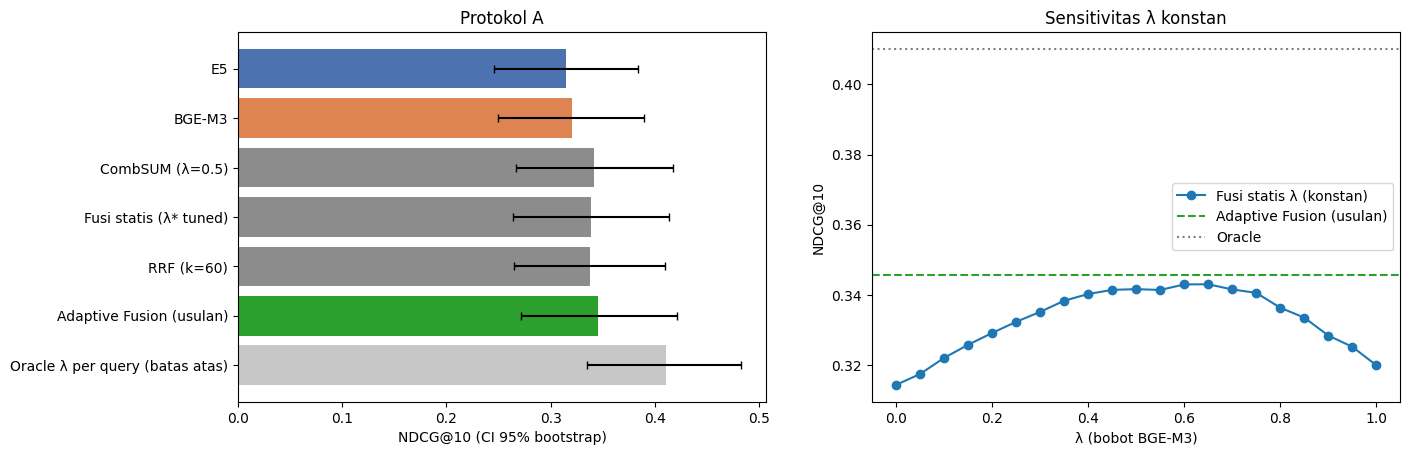

In [16]:
with recorder.stage('Tahap 24 - 9. Evaluasi Protokol A: E5 vs BGE-M3 vs fusi statis vs Adaptive Fusion'):
    # ── Visualisasi ──
    order = main + ['Oracle λ per query (batas atas)']
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    vals = resA.loc[order, 'NDCG@10']
    err = np.abs(ciA.loc[order, ['CI95_low', 'CI95_high']].values.T - vals.values)
    colors = ['#4c72b0', '#dd8452', '#8c8c8c', '#8c8c8c', '#8c8c8c', '#2ca02c', '#c7c7c7']
    ax[0].barh(order, vals, xerr=err, color=colors, capsize=3); ax[0].invert_yaxis()
    ax[0].set_xlabel('NDCG@10 (CI 95% bootstrap)'); ax[0].set_title('Protokol A')

    curve = [ndcg_at(fuse(l, ZBa, ZEa), RELA).mean() for l in CFG['lam_grid']]
    ax[1].plot(CFG['lam_grid'], curve, 'o-', label='Fusi statis λ (konstan)')
    ax[1].axhline(resA.loc[REF, 'NDCG@10'], color='#2ca02c', ls='--', label='Adaptive Fusion (usulan)')
    ax[1].axhline(resA.loc['Oracle λ per query (batas atas)', 'NDCG@10'], color='gray', ls=':', label='Oracle')
    ax[1].set_xlabel('λ (bobot BGE-M3)'); ax[1].set_ylabel('NDCG@10'); ax[1].legend(); ax[1].set_title('Sensitivitas λ konstan')
    display(plt.show())

## 10. Analisis perilaku $\lambda_q$
Bagian ini menjawab *"apa yang dipelajari gating network?"* — penting untuk diskusi di naskah: apakah λ bergeser menurut musim, kategori, dan bahasa query.

/tmp/ipykernel_676/1208583901.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot([lam_df.loc[lam_df.cat == c, 'lambda'] for c in cat_order], vert=False, labels=cat_order)


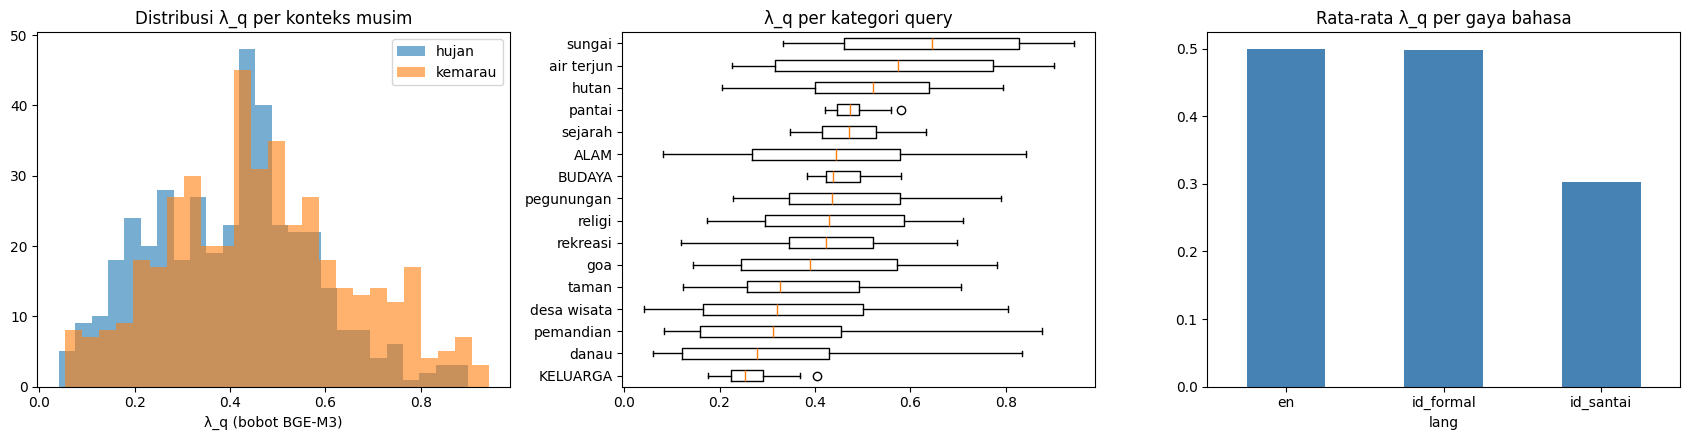

mean    std
season  lang                   
hujan   en         0.488  0.154
        id_formal  0.429  0.149
        id_santai  0.286  0.144
kemarau en         0.510  0.166
        id_formal  0.562  0.176
        id_santai  0.319  0.142

Korelasi Spearman λ_q vs λ_oracle : 0.143


In [17]:
with recorder.stage('Tahap 26 - 10. Analisis perilaku $\\lambda_q$'):
    lam_df = QA[['cat', 'season', 'lang', 'aspect']].copy()
    lam_df['lambda'] = lamA[REF]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for s, g in lam_df.groupby('season'):
        ax[0].hist(g['lambda'], bins=25, alpha=.6, label=s)
    ax[0].set_title('Distribusi λ_q per konteks musim'); ax[0].set_xlabel('λ_q (bobot BGE-M3)'); ax[0].legend()
    cat_order = lam_df.groupby('cat')['lambda'].median().sort_values().index
    ax[1].boxplot([lam_df.loc[lam_df.cat == c, 'lambda'] for c in cat_order], vert=False, labels=cat_order)
    ax[1].set_title('λ_q per kategori query')
    lam_df.groupby('lang')['lambda'].mean().plot.bar(ax=ax[2], color='steelblue', rot=0)
    ax[2].set_title('Rata-rata λ_q per gaya bahasa')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_lambda.png', dpi=300); plt.show()
    display(lam_df.groupby(['season', 'lang'])['lambda'].agg(['mean', 'std']).round(3))

    # Apakah λ yang dipelajari mendekati λ oracle?
    lam_or = oracle(ZBa, ZEa, RELA)
    display(print(f'Korelasi Spearman λ_q vs λ_oracle : {stats.spearmanr(lamA[REF], lam_or).correlation:.3f}'))

## 11. Evaluasi Protokol B (known-item, leave-one-review-out)
- **Zero-shot**: gate dilatih pada seluruh query Protokol A lalu langsung diterapkan pada query ulasan (konteks `none`) → menguji transfer & manfaat *context dropout*.
- **In-domain CV**: gate dilatih ulang pada query Protokol B dengan GroupKFold (grup = destinasi target).

In [18]:
with recorder.stage('Tahap 28 - 11. Evaluasi Protokol B (known-item, leave-one-review-out)'):
    # Gate final (dilatih pada seluruh Protokol A) — juga dipakai fungsi rekomendasi
    fb_final, gates_final = fit_gate_ensemble(FA, ZBa, ZEa, RELA, groupsA, VARIANTS[REF], np.arange(len(QA)))

    FBk = build_feats(SBk['BGE-M3'], SBk['E5'], QBB, QBE, QB_['season'].tolist(), QB_['text'].tolist())
    ZBb, ZEb = ZBk['BGE-M3'], ZBk['E5']
    lamB_zero = predict_ensemble(fb_final, gates_final, FBk)

    groupsB = QB_['did'].values
    lamB_cv, lamB_fix = run_cv(FBk, ZBb, ZEb, RELB, groupsB, {'in-domain': ['qpp', 'emb']})

    S_methods_B = {
        'E5'                                : SBk['E5'],
        'BGE-M3'                            : SBk['BGE-M3'],
        'CombSUM (λ=0.5)'                   : fuse(0.5, ZBb, ZEb),
        'Fusi statis (λ* tuned)'            : fuse(lamB_fix, ZBb, ZEb),
        'RRF (k=60)'                        : rrf(SBk['BGE-M3'], SBk['E5']),
        'Adaptive Fusion (zero-shot dari A)': fuse(lamB_zero, ZBb, ZEb),
        'Adaptive Fusion (in-domain CV)'    : fuse(lamB_cv['in-domain'], ZBb, ZEb),
        'Oracle λ per query (batas atas)'   : fuse(oracle(ZBb, ZEb, RELB), ZBb, ZEb),
    }
    perqB = {m: evaluate(S, RELB) for m, S in S_methods_B.items()}
    resB = summarize(perqB, COLS_B + ['ILD@10', 'Novelty@10'])
    resB['Coverage@10'] = [coverage(S) for S in S_methods_B.values()]
    display(resB.round(4))
    resB.to_csv(f'{OUT_DIR}/hasil_protokolB.csv')

    sigB = significance(perqB, 'Adaptive Fusion (in-domain CV)', 'MRR@10', exclude=('Oracle λ per query (batas atas)',), groups=QB_['did'].values)
    display(sigB.round(4))
    display(sigB.to_csv(f'{OUT_DIR}/signifikansi_protokolB.csv', index=False))

  fold 1/5 selesai | λ* tetap = 0.75
  fold 2/5 selesai | λ* tetap = 0.70
  fold 3/5 selesai | λ* tetap = 0.75
  fold 4/5 selesai | λ* tetap = 0.75
  fold 5/5 selesai | λ* tetap = 0.75


,MRR@10,Hit@1,Hit@5,Hit@10,NDCG@10,ILD@10,Novelty@10,Coverage@10
E5,0.3802,0.2927,0.4934,0.5878,0.4295,0.6361,7.1311,0.9420
BGE-M3,0.4232,0.3346,0.5393,0.6246,0.4712,0.6203,7.1745,0.9565
CombSUM (λ=0.5),0.4240,0.3351,0.5401,0.6281,0.4726,0.6117,7.1211,0.9420
Fusi statis (λ* tuned),0.4302,0.3432,0.5406,0.6306,0.4779,0.6125,7.1375,0.9469
RRF (k=60),0.4111,0.3227,0.5289,0.6172,0.4601,0.6134,7.1125,0.9420
Adaptive Fusion (zero-shot dari A),0.4069,0.3166,0.5241,0.6147,0.4564,0.6229,7.1254,0.9420
Adaptive Fusion (in-domain CV),0.4315,0.3453,0.5431,0.6339,0.4796,0.6175,7.1452,0.9517
Oracle λ per query (batas atas),0.4861,0.3985,0.6015,0.6854,0.5336,0.6287,7.1392,0.9517


,pembanding,delta,cohen_d,win,tie,loss,p_ttest,p_wilcoxon,p_holm,signifikan (α=0.05)
0,E5,0.0489,0.8010,0.7826,0.0628,0.1546,0.0000,0.0000,0.0000,True
1,BGE-M3,0.0080,0.2348,0.5411,0.1208,0.3382,0.0009,0.0009,0.0019,True
2,CombSUM (λ=0.5),0.0073,0.2805,0.5266,0.1449,0.3285,0.0001,0.0003,0.0008,True
3,Fusi statis (λ* tuned),0.0012,0.0618,0.4155,0.1787,0.4058,0.3747,0.5202,0.5202,False
4,RRF (k=60),0.0194,0.4858,0.6232,0.0966,0.2802,0.0000,0.0000,0.0000,True
5,Adaptive Fusion (zero-shot dari A),0.0238,0.5678,0.6667,0.0773,0.2560,0.0000,0.0000,0.0000,True


## 11b. Evaluasi Protokol C — query uji skripsi
Kedua query skripsi dijalankan pada E5 + cosine, BGE-M3 + cosine, fusi statis, dan Adaptive Fusion (gate final yang dilatih pada Protokol A). Karena teks query sama di ketiga konteks musim, **E5 dan BGE-M3 menghasilkan ranking yang sama persis** di setiap konteks — hanya adaptive fusion yang dapat mengubah bobot $\lambda_q$ menurut konteks $c$. Kolom `λ_q` memperlihatkan bobot BGE-M3 yang dipilih gate untuk setiap konteks.

In [19]:
with recorder.stage('Tahap 30 - 11b. Evaluasi Protokol C — query uji skripsi'):
    def top10_relevansi(S_dict, i, k=10):
        """Tabel top-k beberapa sistem untuk query ke-i; ✓ = relevan, ✓✓ = relevan + aspek kuat, ✗ = tidak relevan."""
        mark = {0: '✗', 1: '✓', 2: '✓✓'}
        return pd.DataFrame({m: [f'{dest.destinasi[d]} {mark[int(RELC[i, d])]}' for d in topk_idx(S[i:i + 1], k)[0]]
                             for m, S in S_dict.items()}, index=range(1, k + 1))

    QCB = encode(enc_bge, QC['text'].tolist(), '', 'bge_qC')
    QCE = encode(enc_e5,  QC['text'].tolist(), CFG['e5_query_prefix'], 'e5_qC')
    SCb, SCe = dense_scores(QCB, RB_t), dense_scores(QCE, RE_t)
    ZCb, ZCe = zscore(SCb), zscore(SCe)
    lamC = predict_ensemble(fb_final, gates_final, build_feats(SCb, SCe, QCB, QCE, QC['season'].tolist(), QC['text'].tolist()))

    S_methods_C = {
        'E5'                       : SCe,
        'BGE-M3'                   : SCb,
        'CombSUM (λ=0.5)'          : fuse(0.5, ZCb, ZCe),
        'Fusi statis (λ* tuned)'   : fuse(best_fixed_lambda(ZBa, ZEa, RELA), ZCb, ZCe),
        'Adaptive Fusion (usulan)' : fuse(lamC, ZCb, ZCe),
    }
    perqC = {m: evaluate(S, RELC) for m, S in S_methods_C.items()}
    for m, S in S_methods_C.items():
        perqC[m]['SVR@10'] = season_violation(S, QC['season'])

    COLS_C = ['P@10', 'F1@10', 'MAP@10', 'MRR@10', 'NDCG@10', 'ILD@10', 'SVR@10']
    tabC = pd.concat([QC[['qid', 'status']].assign(metode=m, **{c: perqC[m][c] for c in COLS_C}) for m in S_methods_C],
                     ignore_index=True)
    tabC['λ_q'] = np.nan
    tabC.loc[tabC.metode == 'Adaptive Fusion (usulan)', 'λ_q'] = lamC
    display(tabC.pivot_table(index=['qid', 'status'], columns='metode', values='NDCG@10', sort=False).round(4))
    print('Rata-rata seluruh query Protokol C:')
    display(tabC.groupby('metode', sort=False)[COLS_C].mean().round(4))
    display(QC[['qid', 'status']].assign(**{'λ_q (bobot BGE-M3)': lamC.round(3)}))
    tabC.to_csv(f'{OUT_DIR}/hasil_protokolC.csv', index=False)

    for i in QC.index[QC.status == 'asli skripsi']:
        print(f"\n{QC.qid[i]} (konteks {QC.season[i]}, λ_q = {lamC[i]:.3f}): {QC.text[i]}")
        display(top10_relevansi({m: S_methods_C[m] for m in ['E5', 'BGE-M3', 'Adaptive Fusion (usulan)']}, i))

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

,metode,E5,BGE-M3,CombSUM (λ=0.5),Fusi statis (λ* tuned),Adaptive Fusion (usulan)
qid,status,,,,,
S1-none,asli skripsi,0.9364,0.9337,1.0000,1.0000,1.0000
S1-kemarau,variasi musim,0.9364,0.9337,1.0000,1.0000,1.0000
S1-hujan,variasi musim,0.2122,0.4570,0.3038,0.3191,0.2942
S2-none,variasi musim,0.4802,0.8727,0.7168,0.7357,0.6217
S2-kemarau,asli skripsi,0.4802,0.8727,0.7168,0.7357,0.6217
S2-hujan,variasi musim,0.2973,0.6968,0.5622,0.6025,0.4658


Rata-rata seluruh query Protokol C:


,P@10,F1@10,MAP@10,MRR@10,NDCG@10,ILD@10,SVR@10
metode,,,,,,,
E5,0.5833,0.2116,0.4969,0.8333,0.5571,0.6444,0.65
BGE-M3,0.7667,0.3211,0.7090,1.0000,0.7945,0.5444,0.40
CombSUM (λ=0.5),0.7500,0.2930,0.6469,0.8750,0.7166,0.5111,0.50
Fusi statis (λ* tuned),0.7500,0.2930,0.6759,0.8889,0.7322,0.5556,0.50
Adaptive Fusion (usulan),0.7000,0.2601,0.5979,0.8667,0.6672,0.5778,0.55


,qid,status,λ_q (bobot BGE-M3)
0,S1-none,asli skripsi,0.447
1,S1-kemarau,variasi musim,0.442
2,S1-hujan,variasi musim,0.451
3,S2-none,variasi musim,0.258
4,S2-kemarau,asli skripsi,0.252
5,S2-hujan,variasi musim,0.257



S1-none (konteks none, λ_q = 0.447): Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.


,E5,BGE-M3,Adaptive Fusion (usulan)
1,Taman Wisata Genilangit ✓✓,Sedudo ✓✓,Negeri Atas Angin ✓✓
2,Kawah Ijen ✓✓,Negeri Atas Angin ✓✓,Air Terjun Nglirip ✓✓
3,Buki Teletubies ✓✓,Air Terjun Nglirip ✓✓,Buki Teletubies ✓✓
4,Negeri Atas Angin ✓✓,Kebunteh Sirahkencong ✓✓,Taman Wisata Genilangit ✓✓
5,Air Terjun Nglirip ✓✓,Paralayang ✓✓,Sedudo ✓✓
6,Puncak Ratu ✓✓,Telaga Ngabel ✓✓,Kebunteh Sirahkencong ✓✓
7,Gunung Kelud ✓✓,Hutan Pinus ✓✓,Kawah Ijen ✓✓
8,Wisata Wonosalam ✓✓,Pantai Mutiara ✓✓,Gunung Kelud ✓✓
9,Kebunteh Sirahkencong ✓✓,Kayangan Api ✗,Paralayang ✓✓
10,Selecta ✗,Jamus ✓✓,Pantai Mutiara ✓✓



S2-kemarau (konteks kemarau, λ_q = 0.252): Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmati udara segar.


,E5,BGE-M3,Adaptive Fusion (usulan)
1,Air Terjun Mandakaripuna ✓,Coban Rondo ✓✓,Sedudo ✓✓
2,Sedudo ✓✓,Air Dolo ✓✓,Air Terjun Mandakaripuna ✓
3,Jamus ✗,Sedudo ✓✓,Air Dolo ✓✓
4,Air Dolo ✓✓,Air Terjun Putuk Truno ✓✓,Jamus ✗
5,Air Terjun Nglirip ✓✓,Air terjun Tirtosari ✓✓,Air Terjun Nglirip ✓✓
6,Grogoland ✗,Grogoland ✗,Grogoland ✗
7,Air terjun Dlundung ✓,Air Terjun Mandakaripuna ✓,Air terjun Dlundung ✓
8,Kebunteh Sirahkencong ✗,Coban Pelangi ✓✓,Air Terjun Putuk Truno ✓✓
9,Telaga Ngabel ✗,Air Terjun Nglirip ✓✓,Air Terjun Roro Kuning ✓✓
10,Air Terjun Roro Kuning ✓✓,Air Irenggolo ✓✓,Kebunteh Sirahkencong ✗


## 11c. Evaluasi Protokol D — query uji berbasis literatur
Gate final (dilatih pada Protokol A) diterapkan **tanpa pelatihan ulang** pada query naratif (D1) dan persona × kompleksitas (D2); konteks $c$ diturunkan dari **bulan** perjalanan. Dengan ±260 query, uji signifikansi berpasangan (Wilcoxon + Holm) dapat dilakukan. Analisis tambahan: kinerja per tingkat kompleksitas, per konteks musim, dan **ketahanan terhadap teks persona** (selisih NDCG@10 versi persona − vanilla pada filter yang sama).

In [20]:
with recorder.stage('Tahap 32 - 11c. Evaluasi Protokol D — query uji berbasis literatur'):
    QDB = encode(enc_bge, QD['text'].tolist(), '', 'bge_qD')
    QDE = encode(enc_e5,  QD['text'].tolist(), CFG['e5_query_prefix'], 'e5_qD')
    SDb, SDe = dense_scores(QDB, RB_t), dense_scores(QDE, RE_t)
    ZDb, ZDe = zscore(SDb), zscore(SDe)
    lamD = predict_ensemble(fb_final, gates_final, build_feats(SDb, SDe, QDB, QDE, QD['season'].tolist(), QD['text'].tolist()))

    S_methods_D = {
        'E5'                       : SDe,
        'BGE-M3'                   : SDb,
        'CombSUM (λ=0.5)'          : fuse(0.5, ZDb, ZDe),
        'Fusi statis (λ* tuned)'   : fuse(best_fixed_lambda(ZBa, ZEa, RELA), ZDb, ZDe),
        'RRF (k=60)'               : rrf(SDb, SDe),
        'Adaptive Fusion (usulan)' : fuse(lamD, ZDb, ZDe),
    }
    perqD = {m: evaluate(S, RELD) for m, S in S_methods_D.items()}
    for m, S in S_methods_D.items():
        perqD[m]['SVR@10'] = season_violation(S, QD['season'])
    resD = summarize(perqD, COLS_ACC_A + COLS_BEYOND)
    resD['Coverage@10'] = [coverage(S) for S in S_methods_D.values()]
    print(f'Protokol D — {len(QD)} query'); display(resD.round(4))
    resD.to_csv(f'{OUT_DIR}/hasil_protokolD.csv')

    sigD = significance(perqD, REF, 'NDCG@10', groups=QD['cfg'].values)
    print('Uji berpasangan Adaptive Fusion vs pembanding (NDCG@10):'); display(sigD.round(4))
    sigD.to_csv(f'{OUT_DIR}/signifikansi_protokolD.csv', index=False)

    mainD = list(S_methods_D)
    brkD = pd.DataFrame({m: perqD[m]['NDCG@10'] for m in mainD})
    brkD[['jenis', 'kompleksitas', 'season', 'lang']] = QD[['jenis', 'kompleksitas', 'season', 'lang']].values
    for col in ['jenis', 'kompleksitas', 'season']:
        print(f'\nNDCG@10 per {col}'); display(brkD.groupby(col)[mainD].mean().round(4))

    # Ketahanan terhadap teks persona (pasangan vanilla–persona dengan filter identik)
    pv = QD[QD.jenis.isin(['vanilla', 'persona'])].reset_index()
    rob = {}
    for m in mainD:
        x = pv.assign(v=perqD[m]['NDCG@10'][pv['index']]).pivot_table(index='cfg', columns='jenis', values='v')
        rob[m] = (x['persona'] - x['vanilla']).mean()
    print('Rata-rata Δ NDCG@10 (persona − vanilla); mendekati 0 = tahan terhadap teks persona:')
    display(pd.Series(rob, name='Δ NDCG@10').round(4).to_frame())

    lam_dfD = QD[['jenis', 'season']].assign(lam=lamD)
    print('Rata-rata λ_q (bobot BGE-M3) per jenis × konteks musim:')
    display(display(lam_dfD.pivot_table(index='jenis', columns='season', values='lam').round(3)))

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Protokol D — 260 query


,P@5,P@10,R@10,F1@10,MAP@10,MRR@10,NDCG@5,NDCG@10,Hit@10,ILD@10,Novelty@10,SVR@10,Coverage@10
E5,0.4338,0.3915,0.2524,0.2789,0.3261,0.5877,0.4284,0.4164,0.7923,0.5738,7.1424,0.5123,0.6908
BGE-M3,0.4638,0.3962,0.2512,0.2821,0.3306,0.5760,0.4468,0.4185,0.7885,0.5699,7.2046,0.5589,0.6860
CombSUM (λ=0.5),0.4800,0.4192,0.2678,0.3001,0.3536,0.5914,0.4650,0.4390,0.7769,0.5335,7.1405,0.5671,0.6908
Fusi statis (λ* tuned),0.4800,0.4250,0.2727,0.3049,0.3560,0.5797,0.4607,0.4411,0.7846,0.5290,7.1611,0.5671,0.6908
RRF (k=60),0.4738,0.4100,0.2628,0.2933,0.3489,0.5915,0.4621,0.4341,0.7808,0.5462,7.1402,0.5671,0.6812
Adaptive Fusion (usulan),0.4662,0.4069,0.2613,0.2911,0.3486,0.6006,0.4593,0.4342,0.7846,0.5519,7.1364,0.5438,0.7053


Uji berpasangan Adaptive Fusion vs pembanding (NDCG@10):


...

,E5,BGE-M3,CombSUM (λ=0.5),Fusi statis (λ* tuned),RRF (k=60),Adaptive Fusion (usulan)
season,,,,,,
hujan,0.2154,0.2348,0.2276,0.2352,0.2263,0.2206
kemarau,0.4351,0.4424,0.4599,0.4633,0.4525,0.4546
none,0.5458,0.5311,0.5740,0.5709,0.5686,0.5712


Rata-rata Δ NDCG@10 (persona − vanilla); mendekati 0 = tahan terhadap teks persona:


,Δ NDCG@10
E5,0.1036
BGE-M3,0.0175
CombSUM (λ=0.5),0.0820
Fusi statis (λ* tuned),0.0667
RRF (k=60),0.0895
Adaptive Fusion (usulan),0.0998


Rata-rata λ_q (bobot BGE-M3) per jenis × konteks musim:


season,hujan,kemarau,none
jenis,,,
naratif,0.264,0.314,0.401
persona,0.171,0.183,0.299
vanilla,0.399,0.449,0.668


## 12. Sistem rekomendasi adaptif (inferensi) + studi kasus
Fungsi `rekomendasi(query, musim)` mengimplementasikan diagram secara utuh dan mengembalikan top-k destinasi, $\lambda_q$, kecocokan musim, serta **ulasan bukti** (ulasan dengan skor fusi tertinggi pada destinasi tersebut) sebagai penjelasan rekomendasi.

In [21]:
with recorder.stage('Tahap 34 - 12. Sistem rekomendasi adaptif (inferensi) + studi kasus'):
    def rekomendasi(query, musim='hujan', k=10, filter_musim=False):
        musim = musim if musim in CTX_IDX else 'none'
        t0 = time.time()
        qB = encode(enc_bge, [query]); qE = encode(enc_e5, [query], CFG['e5_query_prefix'])
        sB, sE = dense_scores(qB, RB_t), dense_scores(qE, RE_t)
        lam = float(predict_ensemble(fb_final, gates_final, build_feats(sB, sE, qB, qE, [musim], [query]))[0])
        s = fuse(lam, zscore(sB), zscore(sE))[0]
        if filter_musim and musim == 'hujan':
            s = np.where(NOT_RAIN, -np.inf, s)
        valid = np.flatnonzero(np.isfinite(s))
        top = valid[np.argsort(-s[valid], kind='stable')[:k]]
        latency = time.time() - t0
        simB = (RB_t @ torch.from_numpy(qB[0]).to(DEVICE, DTYPE)).float().cpu().numpy()
        simE = (RE_t @ torch.from_numpy(qE[0]).to(DEVICE, DTYPE)).float().cpu().numpy()
        sim = lam * simB + (1 - lam) * simE
        bukti = [df['text'].iat[OFFSETS[d] + int(np.argmax(sim[OFFSETS[d]:OFFSETS[d + 1]]))][:160] for d in top]
        out = dest.iloc[top][['destinasi', 'wisata', 'musim', 'rating_mean']].assign(
            skor=s[top].round(3), skor_BGE=zscore(sB)[0, top].round(3), skor_E5=zscore(sE)[0, top].round(3),
            ulasan_bukti=bukti).reset_index(drop=True)
        out.index += 1
        print(f'Query: "{query}" | musim: {musim} | λ_q = {lam:.3f} (BGE-M3) / {1 - lam:.3f} (E5) | latensi {latency * 1000:.0f} ms')
        return out

    display(rekomendasi('wisata alam saat musim hujan', 'hujan'))
    display(rekomendasi('pantai yang bersih dan cocok untuk keluarga', 'kemarau'))
    display(display(rekomendasi('quiet waterfall with cool air', 'none')))

Query: "wisata alam saat musim hujan" | musim: hujan | λ_q = 0.557 (BGE-M3) / 0.443 (E5) | latensi 182 ms


,destinasi,wisata,musim,rating_mean,skor,skor_BGE,skor_E5,ulasan_bukti
1,Taman Nasional Baluran,hutan/perkebunan,Kemarau & Penghujan,4.641444,2.048,2.246,1.800,Seru sayang pas kesana lagi musim hujan
2,Air Terjun Nglirip,air terjun,Kemarau,4.602740,1.963,1.976,1.946,Wisata alam yg sejuk
3,Buki Teletubies,pegunungan,Kemarau,4.746006,1.847,1.940,1.730,Lebih hijau saat musim hujan
4,Waduk Pacal,danau/waduk,Kemarau,4.371212,1.759,1.469,2.124,wisata alam murah meriah
5,Wana Wisata Grape,rekreasi/edukasi,Kemarau,4.253521,1.754,1.847,1.638,Tempat wisata alam
6,Kebunteh Sirahkencong,hutan/perkebunan,Kemarau,4.629397,1.547,1.487,1.622,Wisata alam yang menakjubkan
7,Sedudo,air terjun,Kemarau & Penghujan,4.603531,1.532,1.368,1.738,Pengalaman yang menyenangkanSayang datang pas hujan
8,Negeri Atas Angin,pegunungan,Kemarau,4.294479,1.532,1.656,1.375,Tempat wisata alam yang murah meriah
9,Taman Safari Prigen,rekreasi/edukasi,Kemarau & Penghujan,4.524966,1.513,1.457,1.584,Wahana banyak tutup saat hujan
10,Selecta,rekreasi/edukasi,Kemarau,4.698132,1.495,1.566,1.406,Tempat wisata alam


Query: "pantai yang bersih dan cocok untuk keluarga" | musim: kemarau | λ_q = 0.540 (BGE-M3) / 0.460 (E5) | latensi 169 ms


,destinasi,wisata,musim,rating_mean,skor,skor_BGE,skor_E5,ulasan_bukti
1,Pantai Mutiara,pantai,Kemarau,4.475236,2.452,2.366,2.554,Pantai cocok buat kluarga
2,Pantai Ngliyep,pantai,Kemarau,4.623870,1.976,1.867,2.103,Pantainya bagus bersih healing bareng keluarga cocok banget
3,Pantai Pasir Putih,pantai,Kemarau & Penghujan,4.391089,1.942,1.849,2.053,Pantai cantik nan bersih layak buat santai bersama keluarga sambil menikmati senja
4,Pantai Watuulo,pantai,Kemarau,4.306173,1.903,1.810,2.013,Pantai yg indah dan nyaman buat liburan keluarga
5,Pantai Watu Karang,pantai,Kemarau,4.754508,1.898,1.878,1.923,Pantai yang bagus untuk liburan keluarga
6,Pantai Serang,pantai,Kemarau,4.599034,1.898,1.977,1.804,Pantai yg nyaman untuk destinasi wisata keluarga
7,Pantai Lon Malang,pantai,Kemarau,4.360887,1.880,1.777,2.002,Pantai yang cukup indah buat liburan bareng keluarga
8,Pantai Balekambang,pantai,Kemarau & Penghujan,4.000000,1.875,1.992,1.737,pantai yang bagus buat keluarga
9,Pantai Telengria,pantai,Kemarau,4.408736,1.840,1.884,1.788,Pantai yg bersih dan nyaman untuk bersantai
10,Pantai Srau,pantai,Kemarau,4.702970,1.782,1.509,2.103,Pantai favorit.. Nyaman buat keluarga


Query: "quiet waterfall with cool air" | musim: none | λ_q = 0.776 (BGE-M3) / 0.224 (E5) | latensi 131 ms


,destinasi,wisata,musim,rating_mean,skor,skor_BGE,skor_E5,ulasan_bukti
1,Air Terjun Toroan,air terjun,Kemarau & Penghujan,4.428191,2.028,1.975,2.214,"Good Waterfall, short trekking and good for chillin"
2,Sedudo,air terjun,Kemarau & Penghujan,4.603531,2.006,1.889,2.412,Suasana yang tenang dengan air terjun yang indah
3,Kebunteh Sirahkencong,hutan/perkebunan,Kemarau,4.629397,1.649,1.641,1.677,"sejuk, adem jauh dari kebisingan"
4,Air Terjun Nglirip,air terjun,Kemarau,4.602740,1.398,1.347,1.578,Pemandangan yg asri dan udara yg sejuk. Nice Place
5,Grogoland,rekreasi/edukasi,Kemarau & Penghujan,4.487113,1.391,1.403,1.351,Tempat sejuk airnya alami
6,Air Terjun Mandakaripuna,air terjun,Kemarau,4.014257,1.354,1.069,2.342,"Nice waterfall, near bromo."
7,Goal Selomangleng,goa,Kemarau,4.504651,1.343,1.555,0.604,Suasana tenang dan sejuk
8,Air Terjuntumpaksewu,air terjun,Kemarau,4.762749,1.324,1.244,1.602,Air terjun yg dingin
9,Negeri Atas Angin,pegunungan,Kemarau,4.294479,1.301,1.280,1.374,Tenang Damai Dan Sejuk
10,Air terjun Dlundung,air terjun,Kemarau,4.446154,1.300,1.164,1.771,Beautiful waterfall landscape


In [22]:
with recorder.stage('Tahap 35 - 12. Sistem rekomendasi adaptif (inferensi) + studi kasus'):
    # ── Studi kasus: bandingkan top-10 E5, BGE-M3, dan Adaptive untuk query contoh di diagram ──
    q = 'wisata alam saat musim hujan'
    qb, qe = encode(enc_bge, [q]), encode(enc_e5, [q], CFG['e5_query_prefix'])
    sb, se = dense_scores(qb, RB_t), dense_scores(qe, RE_t)
    lam = float(predict_ensemble(fb_final, gates_final, build_feats(sb, se, qb, qe, ['hujan'], [q]))[0])
    rel_q = (dest['wisata'].isin(CATS['ALAM'][0]) & dest['cocok_hujan']).values
    case = pd.DataFrame({
        'E5'      : dest['destinasi'].values[topk_idx(se, 10)[0]],
        'BGE-M3'  : dest['destinasi'].values[topk_idx(sb, 10)[0]],
        f'Adaptive (λ={lam:.2f})': dest['destinasi'].values[topk_idx(fuse(lam, zscore(sb), zscore(se)), 10)[0]],
    }, index=range(1, 11))
    display(case)
    for name, S_ in [('E5', se), ('BGE-M3', sb), ('Adaptive', fuse(lam, zscore(sb), zscore(se)))]:
        print(f'{name:9s} relevan@10 = {int(rel_q[topk_idx(S_, 10)[0]].sum())}/10 | '
              f'tidak cocok musim hujan @10 = {int(NOT_RAIN[topk_idx(S_, 10)[0]].sum())}')

,E5,BGE-M3,Adaptive (λ=0.56)
1,Taman Rajekwesi,Taman Nasional Baluran,Taman Nasional Baluran
2,Waduk Pacal,Air Terjun Nglirip,Air Terjun Nglirip
3,Air Terjun Mandakaripuna,Buki Teletubies,Buki Teletubies
4,Air Terjun Nglirip,Wana Wisata Grape,Waduk Pacal
5,Taman Nasional Baluran,Kayangan Api,Wana Wisata Grape
6,Air Terjun Kedung Maor,Negeri Atas Angin,Kebunteh Sirahkencong
7,Sedudo,Selecta,Sedudo
8,Buki Teletubies,Pantai Telengria,Negeri Atas Angin
9,Wana Wisata Grape,Kebunteh Sirahkencong,Taman Safari Prigen
10,Kebunteh Sirahkencong,Waduk Pacal,Selecta


E5        relevan@10 = 2/10 | tidak cocok musim hujan @10 = 7
BGE-M3    relevan@10 = 1/10 | tidak cocok musim hujan @10 = 8
Adaptive  relevan@10 = 2/10 | tidak cocok musim hujan @10 = 7


## 13. Validasi anotasi manusia (disarankan kuat untuk Q1)
*Qrels* Protokol A bersifat *silver* (diturunkan dari metadata). Untuk Q1, ambil ±50 query uji, **pooling** top-10 dari E5, BGE-M3, dan Adaptive, lalu minta **2–3 anotator** menilai relevansi 0/1/2 tanpa mengetahui sistem asal (*blind*). Laporkan **Cohen's κ (weighted)** antar-anotator dan hitung ulang metrik dengan label manusia.

In [23]:
with recorder.stage('Tahap 37 - 13. Validasi anotasi manusia (disarankan kuat untuk Q1)'):
    rng = np.random.default_rng(7)
    pool_q = rng.choice(len(QA), size=min(50, len(QA)), replace=False)
    pool_rows = []
    for qi in pool_q:
        cand = set()
        for m in ['E5', 'BGE-M3', REF]:
            cand |= set(topk_idx(S_methods_A[m][qi:qi + 1], 10)[0])
        for d in rng.permutation(sorted(cand)):       # diacak agar anotator tidak tahu asal sistem
            sample = df['text'].iloc[OFFSETS[d]:OFFSETS[d + 1]].sample(min(3, dest.n_ulasan[d]), random_state=0).str[:200]
            pool_rows.append(dict(qid=int(qi), query=QA.text[qi], destinasi=dest.destinasi[d], kategori=dest.wisata[d],
                                  musim=dest.musim[d], contoh_ulasan=' || '.join(sample),
                                  label_anotator1='', label_anotator2=''))
    pd.DataFrame(pool_rows).to_csv(f'{OUT_DIR}/pool_anotasi_manusia.csv', index=False)
    print(f'Pool anotasi: {len(pool_rows)} pasangan (query, destinasi) → {OUT_DIR}/pool_anotasi_manusia.csv')

    def evaluasi_anotasi(path):
        """Jalankan setelah CSV pool diisi (label 0/1/2)."""
        ann = pd.read_csv(path).dropna(subset=['label_anotator1', 'label_anotator2'])
        kappa = cohen_kappa_score(ann.label_anotator1.astype(int), ann.label_anotator2.astype(int), weights='quadratic')
        ann['rel'] = np.floor((ann.label_anotator1 + ann.label_anotator2) / 2).astype(int)
        qids = sorted(ann.qid.unique())
        REL_H = np.zeros((len(qids), D), np.int8)
        for i, qi in enumerate(qids):
            for _, r in ann[ann.qid == qi].iterrows():
                REL_H[i, dest_id[r.destinasi]] = r.rel
        res = summarize({m: evaluate(S_methods_A[m][qids], REL_H) for m in main}, ['NDCG@10', 'MAP@10', 'P@10'])
        print(f"Weighted Cohen's κ = {kappa:.3f}")
        return res

Pool anotasi: 802 pasangan (query, destinasi) → /content/drive/MyDrive/Rekomendasi_Wisata/output_fusion_research/20261026_013728_f26eb3/pool_anotasi_manusia.csv


## 14. Ringkasan & ekspor tabel untuk naskah

## Pemilihan validasi dan ekspor bundle Streamlit
Oracle dilarang menjadi calon deployment. Mock selalu ditandai tidak layak deployment.

In [24]:
with recorder.stage('Tahap 40 - Pemilihan validasi dan ekspor bundle Streamlit'):
    # Sel ini disisipkan ke notebook; bukan CLI mandiri.
    selection_train, selection_val = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
        random_state=2026).split(np.arange(len(QA)), groups=groupsA))
    selection_fb, selection_gates = fit_gate_ensemble(FA, ZBa, ZEa, RELA, groupsA,
        VARIANTS[REF], selection_train, seed_split=2026)
    selection_lambda = predict_ensemble(selection_fb, selection_gates, subset(FA, selection_val))
    selection_scores = {
        'BGE-M3': float(ndcg_at(SA['BGE-M3'][selection_val], RELA[selection_val]).mean()),
        'E5': float(ndcg_at(SA['E5'][selection_val], RELA[selection_val]).mean()),
        REF: float(ndcg_at(fuse(selection_lambda, ZBa[selection_val], ZEa[selection_val]), RELA[selection_val]).mean()),
    }
    selected_method = max(selection_scores, key=selection_scores.get)
    display(pd.Series(selection_scores, name='NDCG@10 validasi pemilihan').to_frame())
    print('Calon serving:', selected_method, '| Layak deployment:', not MOCK)
    print('Pemilihan ini berbasis validasi kelompok kategori, bukan oracle atau skor test.')

    from pathlib import Path
    import shutil
    bundle = Path(OUT_DIR) / ('bundle_mock_DO_NOT_DEPLOY' if MOCK else 'bundle_streamlit')
    bundle.mkdir(parents=True, exist_ok=True)
    df[['destinasi','text','did']].to_json(bundle/'reviews.json', orient='records', force_ascii=False)
    dest.to_json(bundle/'catalog.json', orient='records', force_ascii=False)
    np.save(bundle/'bge.npy', RB, allow_pickle=False)
    np.save(bundle/'e5.npy', RE, allow_pickle=False)
    np.save(bundle/'offsets.npy', OFFSETS, allow_pickle=False)
    np.savez(bundle/'preprocess.npz', pca_mean=fb_final.pca.mean_, pca_components=fb_final.pca.components_,
        scaler_mean=fb_final.scaler.mean_, scaler_scale=fb_final.scaler.scale_)
    for i, gate in enumerate(gates_final):
        torch.save(gate.state_dict(), bundle/f'gate_{i}.pt')
    manifest = {
        'schema':1, 'mock':MOCK, 'eligible_for_deployment':not MOCK,
        'selected_method':selected_method, 'selection_metric':'NDCG@10 grouped validation',
        'selection_scores':selection_scores, 'selection_train_query_ids':selection_train.tolist(),
        'selection_validation_query_ids':selection_val.tolist(),
        'dataset_sha256':DATASET_SHA256, 'reviews':int(N), 'destinations':int(D),
        'scope':'entire uploaded workbook; Jawa Timur; no Madura filter',
        'bge_model':CFG['bge_model'], 'bge_revision':CFG['bge_revision'],
        'e5_model':CFG['e5_model'], 'e5_revision':CFG['e5_revision'],
        'max_len':CFG['max_len'], 'topm':CFG['topm'], 'gate_hidden':CFG['gate_hidden'],
        'gate_dropout':CFG['gate_dropout'], 'ensemble_size':len(gates_final),
        'input_dim':int(fb_final.transform(FA).shape[1]),
        'query_context':['hujan','kemarau','none'],
        'evaluation_warning':'Silver metadata qrels; category groups can share relevant destinations; not human relevance judgments',
        'files':{},
    }
    for path in sorted(bundle.iterdir()):
        if path.name != 'manifest.json':
            manifest['files'][path.name] = hashlib.sha256(path.read_bytes()).hexdigest()
    (bundle/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    from wisata.fusion_serving import load_gate_ensemble, gate_features
    check_ids = np.arange(min(5,len(QA)))
    loaded_gates = load_gate_ensemble(bundle,manifest)
    check_features = fb_final.transform(subset(FA,check_ids))
    with torch.inference_mode():
        loaded_lambda = np.mean([torch.sigmoid(g(torch.from_numpy(check_features))).numpy().ravel()
                                for g in loaded_gates],axis=0)
    np.testing.assert_allclose(loaded_lambda,predict_ensemble(fb_final,gates_final,subset(FA,check_ids)),atol=1e-6)
    with np.load(bundle/'preprocess.npz',allow_pickle=False) as processor:
        check_row = gate_features(SA['BGE-M3'][:1],SA['E5'][:1],QAB[:1],QAE[:1],QA.season.iloc[0],QA.text.iloc[0],processor)
    np.testing.assert_allclose(check_row,check_features[:1],atol=1e-5)
    print('Pemeriksaan ekspor: lambda dan preprocessing bundle cocok dengan notebook.')
    shutil.make_archive(str(bundle), 'zip', bundle)
    print('Bundle:', bundle, '| ZIP:', str(bundle)+'.zip')
    display(print('PDF setiap tahap:', Path(REPORT_DIR)/'hasil.pdf'))

,NDCG@10 validasi pemilihan
BGE-M3,0.399397
E5,0.371762
Adaptive Fusion (usulan),0.436049


Calon serving: Adaptive Fusion (usulan) | Layak deployment: True
Pemilihan ini berbasis validasi kelompok kategori, bukan oracle atau skor test.
Pemeriksaan ekspor: lambda dan preprocessing bundle cocok dengan notebook.
Bundle: /content/drive/MyDrive/Rekomendasi_Wisata/output_fusion_research/20261026_013728_f26eb3/bundle_streamlit | ZIP: /content/drive/MyDrive/Rekomendasi_Wisata/output_fusion_research/20261026_013728_f26eb3/bundle_streamlit.zip
PDF setiap tahap: /content/drive/MyDrive/Rekomendasi_Wisata/reports_research/20261026_013728_f26eb3/hasil.pdf


In [25]:
with recorder.stage('Tahap 41 - Pemilihan validasi dan ekspor bundle Streamlit'):
    summary = {
        'n_ulasan': int(N), 'n_destinasi': int(D), 'n_query_A': int(len(QA)), 'n_query_B': int(len(QB_)),
        'mock': MOCK, 'config': {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in CFG.items()},
        'protokolA_NDCG@10': resA['NDCG@10'].round(4).to_dict(),
        'protokolB_MRR@10': resB['MRR@10'].round(4).to_dict(),
        'protokolC_NDCG@10': tabC.groupby('metode', sort=False)['NDCG@10'].mean().round(4).to_dict(),
        'protokolD_NDCG@10': resD['NDCG@10'].round(4).to_dict(),
    }
    with open(f'{OUT_DIR}/ringkasan.json', 'w', encoding='utf-8') as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    pd.DataFrame({'qid': range(len(QA)), 'lambda_adaptive': lamA[REF], 'lambda_oracle': lam_or}).to_csv(
        f'{OUT_DIR}/lambda_per_query.csv', index=False)

    # Metrik per query semua metode (dipakai notebook E5 untuk uji berpasangan)
    def perq_frame(perq, protokol):
        return pd.concat([pd.DataFrame({'protokol': protokol, 'qid': np.arange(len(v['NDCG@10'])), 'metode': m, **v})
                          for m, v in perq.items()], ignore_index=True)
    pd.concat([perq_frame(perqA, 'A'), perq_frame(perqB, 'B'), perq_frame(perqC, 'C'), perq_frame(perqD, 'D')]).to_csv(f'{OUT_DIR}/metrik_per_query.csv', index=False)

    # Konsistensi dengan notebook [1] BGE-M3 + cosine dan [2] E5 + cosine (jika output-nya ditambahkan sebagai input)
    for tag, m in [('bge', 'BGE-M3'), ('e5', 'E5')]:
        cands = [p for p in [os.path.join(WORK_DIR, f'output_{tag}', f'metrik_per_query_{tag}.csv')] if os.path.exists(p)]
        if not cands:
            print(f'metrik_per_query_{tag}.csv tidak ditemukan — cek konsistensi dengan notebook {m} dilewati')
            continue
        x = pd.read_csv(cands[0]); x = x[(x.protokol == 'A') & (x.metode == x.metode.iloc[0])].sort_values('qid')
        diff = np.abs(x['NDCG@10'].values - perqA[m]['NDCG@10']).max() if len(x) == len(QA) else np.inf
        print(f'{m}: selisih maks NDCG@10 per query vs notebook terpisah = {diff:.2e} (≈0 = identik)')

    for name, tab in [('tabel_protokolA', resA.loc[order]), ('tabel_protokolB', resB)]:
        try:
            with open(f'{OUT_DIR}/{name}.tex', 'w', encoding='utf-8') as f:
                f.write(tab.round(4).to_latex(float_format='%.4f'))
        except Exception as e:
            print('LaTeX dilewati:', e)

    print(json.dumps({k: summary[k] for k in ['protokolA_NDCG@10', 'protokolB_MRR@10', 'protokolC_NDCG@10', 'protokolD_NDCG@10']}, indent=2, ensure_ascii=False))
    display(print('\nFile keluaran:', sorted(os.listdir(OUT_DIR))))

metrik_per_query_bge.csv tidak ditemukan — cek konsistensi dengan notebook BGE-M3 dilewati
metrik_per_query_e5.csv tidak ditemukan — cek konsistensi dengan notebook E5 dilewati
{
  "protokolA_NDCG@10": {
    "E5": 0.3143,
    "BGE-M3": 0.32,
    "CombSUM (λ=0.5)": 0.3416,
    "Fusi statis (λ* tuned)": 0.3381,
    "RRF (k=60)": 0.3373,
    "Adaptive Fusion (usulan)": 0.3458,
    "Ablasi: tanpa konteks c": 0.3462,
    "Ablasi: tanpa fitur QPP": 0.3429,
    "Ablasi: tanpa embedding q": 0.346,
    "Ablasi: konteks saja": 0.3398,
    "Oracle λ per query (batas atas)": 0.4101
  },
  "protokolB_MRR@10": {
    "E5": 0.3802,
    "BGE-M3": 0.4232,
    "CombSUM (λ=0.5)": 0.424,
    "Fusi statis (λ* tuned)": 0.4302,
    "RRF (k=60)": 0.4111,
    "Adaptive Fusion (zero-shot dari A)": 0.4069,
    "Adaptive Fusion (in-domain CV)": 0.4315,
    "Oracle λ per query (batas atas)": 0.4861
  },
  "protokolC_NDCG@10": {
    "E5": 0.5571,
    "BGE-M3": 0.7945,
    "CombSUM (λ=0.5)": 0.7166,
    "Fusi statis 

## 15. Catatan untuk penulisan naskah (Q1)

Daftar pustaka lengkap (penelitian acuan query uji, model, dan metode) ada di **Bagian 3**.

**Pertanyaan penelitian yang dijawab notebook ini**
- *RQ1*: Seberapa baik E5 dan BGE-M3 (sendiri-sendiri) untuk rekomendasi destinasi sadar-musim berbahasa Indonesia, dan seberapa komplementer keduanya? → Bagian 7.
- *RQ2*: Apakah *adaptive fusion* mengungguli fusi statis (CombSUM, λ terbaik, RRF) secara signifikan? → Bagian 9 (Wilcoxon + Holm, CI bootstrap).
- *RQ3*: Komponen mana yang paling berkontribusi (konteks musim, QPP, embedding query)? → baris *Ablasi*.
- *RQ4*: Apa yang dipelajari gating network dan apakah ia mentransfer ke query bebas (ulasan)? → Bagian 10 & 11.

**Hal yang wajib dilaporkan jujur (*threats to validity*)**
1. Label musim berasal dari BGE-M3 (bias sirkular) → laporkan, dan perkuat dengan anotasi manusia (Bagian 13) atau label musim independen (mis. data curah hujan BMKG per lokasi).
2. *Qrels* Protokol A berbasis metadata & leksikon (*silver*); Protokol B hanya satu item relevan per query.
3. Cakupan satu provinsi (Jawa Timur); generalisasi ke wilayah lain belum diuji.
4. Jika selisih Adaptive vs λ* tuned kecil/tidak signifikan, laporkan apa adanya dan tonjolkan keunggulan lain (robust lintas bahasa, tanpa *tuning* λ manual, bekerja saat konteks tidak diketahui, interpretabilitas λ).

**Penguatan opsional sebelum submit**: tambahkan BGE-M3 *sparse/ColBERT* sebagai sinyal ketiga (gating multi-ekspert/softmax), bandingkan dengan *cross-encoder reranker* (`BAAI/bge-reranker-v2-m3`), dan uji sensitivitas `topm` ∈ {1, 3, 5, 10} serta `tau`.